# IMPORTS

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.colors import to_hex
from tqdm import tqdm, trange

import time
from IPython.display import display
import os
import re

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.feature_selection import f_classif, SelectKBest
from sklearn.feature_selection import VarianceThreshold
from sklearn.feature_selection import RFE
from imblearn.over_sampling import SMOTE

import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from collections import Counter
from sklearn.metrics import make_scorer, precision_score, recall_score, accuracy_score, precision_recall_curve, roc_auc_score, confusion_matrix
from sklearn.metrics import average_precision_score, log_loss, f1_score, brier_score_loss, balanced_accuracy_score

from threadpoolctl import threadpool_limits


import torch
import torch.nn as nn

import lime
import lime.lime_tabular
import json, math, pathlib


from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LassoCV, Lasso
import warnings
from sklearn.pipeline import Pipeline



os.environ["OMP_NUM_THREADS"] = "1"  # quiet MKL/MKL-threads warning on Windows

# DATA: radiomics + tabular_data

## Methods: import data from csv's, clean and split

In [34]:
from get_data import get_data

## experiments: wich data its imported and how it's splitted

Experimentos:

* Solo EGD con IDH
* Solo EGD con 1P19Q
* Solo PDGM con IDH
* Solo PDGM con IDH test sobre EGD
* Solo LGG con 1P19Q
* Split EGD + PDGM para train

In [35]:
# Chose wich database use
experiments = ['EGD_IDH', 'EGD_COD', 'PDGM', 'PDGM_TEST_EGD', 'LGG', 'TRAIN_EGD_PDGM']
experiment = experiments[1]
RANDOM_STATE=42
TEST_SIZE=0.15

train_df, test_df = get_data(experiment, TEST_SIZE, RANDOM_STATE)

########## TRAIN

#### 1p19q
grade_train_label = train_df[train_df['Label']!=-1]['Grade']
class_train_label = train_df[train_df['Label']!=-1]['Class']
y_train_label = train_df[train_df['Label']!=-1]['Label']
x_train_label = train_df[train_df['Label']!=-1].iloc[:, :-4]

#### IDH
grade_train_idh = train_df[train_df['IDH']!=-1]['Grade']
class_train_idh = train_df[train_df['IDH']!=-1]['Class']
y_train_idh = train_df[train_df['IDH']!=-1]['IDH']
x_train_idh = train_df[train_df['IDH']!=-1].iloc[:, :-4]

#### Merged
grade_train_merged = train_df[(train_df['IDH']==1) & (train_df['Label']!=-1) & (train_df['Grade']<4)]['Grade']
class_train_merged = train_df[(train_df['IDH']==1) & (train_df['Label']!=-1) & (train_df['Grade']<4)]['Class']
y_train_merged = train_df[(train_df['IDH']==1) & (train_df['Label']!=-1) & (train_df['Grade']<4)]['Label']
x_train_merged = train_df[(train_df['IDH']==1) & (train_df['Label']!=-1) & (train_df['Grade']<4)].iloc[:, :-4]

y_train_merged_idh0 = train_df[(train_df['IDH']==0) & (train_df['Label']!=-1) & (train_df['Grade']<4)]['Label']
x_train_merged_idh0 = train_df[(train_df['IDH']==0) & (train_df['Label']!=-1) & (train_df['Grade']<4)].iloc[:, :-4]

########## TEST

#### 1p19q
grade_test_label = test_df[test_df['Label']!=-1]['Grade']
class_test_label = test_df[test_df['Label']!=-1]['Class']
y_test_label = test_df[test_df['Label']!=-1]['Label']
x_test_label = test_df[test_df['Label']!=-1].iloc[:, :-4]

#### IDH
grade_test_idh = test_df[test_df['IDH']!=-1]['Grade']
class_test_idh = test_df[test_df['IDH']!=-1]['Class']
y_test_idh = test_df[test_df['IDH']!=-1]['IDH']
x_test_idh = test_df[test_df['IDH']!=-1].iloc[:, :-4]

#### Merged
grade_test_merged = test_df[(test_df['IDH']==1) & (test_df['Label']!=-1) & (test_df['Grade']<4)]['Grade']
class_test_merged = test_df[(test_df['IDH']==1) & (test_df['Label']!=-1) & (test_df['Grade']<4)]['Class']
y_test_merged = test_df[(test_df['IDH']==1) & (test_df['Label']!=-1) & (test_df['Grade']<4)]['Label']
x_test_merged = test_df[(test_df['IDH']==1) & (test_df['Label']!=-1) & (test_df['Grade']<4)].iloc[:, :-4]


##################### DATA STANDARIZATION AND NORMALIZATION
# The standarization and normalization goes before the merge

# Standardize the DataFrame
std_scaler = StandardScaler()

x_train_label_scaled = std_scaler.fit_transform(x_train_label)
x_test_label_scaled = std_scaler.transform(x_test_label)
x_train_idh_scaled = std_scaler.fit_transform(x_train_idh)
x_test_idh_scaled = std_scaler.transform(x_test_idh)
x_train_merged_scaled = std_scaler.fit_transform(x_train_merged)
x_test_merged_scaled = std_scaler.transform(x_test_merged)

#x_train_merged_idh0_scaled = std_scaler.fit_transform(x_train_merged_idh0)


# Initialize the MinMaxScaler
minmax_scaler = MinMaxScaler()

###### MINMAX IS BEING IGNORED
# Normalize the features
x_train_label_normalized = minmax_scaler.fit_transform(x_train_label_scaled)
x_test_label_normalized = minmax_scaler.transform(x_test_label_scaled)
x_train_idh_normalized = minmax_scaler.fit_transform(x_train_idh_scaled)
x_test_idh_normalized = minmax_scaler.transform(x_test_idh_scaled)
x_train_merged_normalized = minmax_scaler.fit_transform(x_train_merged_scaled)
x_test_merged_normalized = minmax_scaler.transform(x_test_merged_scaled)
#x_train_merged_idh0_normalized = minmax_scaler.fit_transform(x_train_merged_idh0_scaled)


# Convert back to DataFrame with original column names
x_train_label = pd.DataFrame(x_train_label_scaled, columns=x_train_label.columns)
x_test_label = pd.DataFrame(x_test_label_scaled, columns=x_test_label.columns)
x_train_idh = pd.DataFrame(x_train_idh_scaled, columns=x_train_idh.columns)
x_test_idh = pd.DataFrame(x_test_idh_scaled, columns=x_test_idh.columns)
x_train_merged = pd.DataFrame(x_train_merged_scaled, columns=x_train_merged.columns)
x_test_merged = pd.DataFrame(x_test_merged_scaled, columns=x_test_merged.columns)

#x_train_merged_idh0 = pd.DataFrame(x_train_merged_idh0_normalized, columns=x_train_merged_idh0.columns)


#x_train_label_original, x_train_label_clahe = split_df(x_train_label)
#x_train_idh_original, x_train_idh_clahe = split_df(x_train_idh)
#x_train_merged_original, x_train_merged_clahe = split_df(x_train_merged)

#x_test_label_original, x_test_label_clahe = split_df(x_test_label)
#x_test_idh_original, x_test_idh_clahe = split_df(x_test_idh)
#x_test_merged_original, x_test_merged_clahe = split_df(x_test_merged)

mirrored_x_train_idh = x_train_idh.filter(like='mirrored')
mirrored_x_train_label = x_train_label.filter(like='mirrored')
mirrored_x_train_merged = x_train_merged.filter(like='mirrored')

difference_x_train_idh = x_train_idh.filter(like='difference')
difference_x_train_label = x_train_label.filter(like='difference')
difference_x_train_merged = x_train_merged.filter(like='difference')

border_x_train_idh = x_train_idh.filter(like='border')
border_x_train_label = x_train_label.filter(like='border')
border_x_train_merged = x_train_merged.filter(like='border')

# Define a regular expression pattern to match columns containing 'mirrored' or 'difference'
pattern = 'mirrored|difference|border'

# Use the filter method to select columns matching the pattern
columns_to_drop = x_train_idh.filter(regex=pattern).columns
original_x_train_idh = x_train_idh.drop(columns=columns_to_drop)
columns_to_drop = x_train_label.filter(regex=pattern).columns
original_x_train_label = x_train_label.drop(columns=columns_to_drop)
columns_to_drop = x_train_merged.filter(regex=pattern).columns
original_x_train_merged = x_train_merged.drop(columns=columns_to_drop)

#
original_x_train_idh = original_x_train_idh.drop(columns=['Age', 'Sex'])
original_x_train_label = original_x_train_label.drop(columns=['Age', 'Sex'])
original_x_train_merged = original_x_train_merged.drop(columns=['Age', 'Sex'])


print(f'full datasets Features: {len(x_train_idh.columns)}')
# {-} = label -> predict 1p19q     {-} = idh -> predict idh        {-} = merged for any (no unkonwn for  any label)
# x_train_{-} train data for predicting {-}
# y_train_{-} labels {-} for training
# x_test_{-} test data for predicting {-}
# y_test_{-} labels {-} for testing
# class_train_{-} tumor name for training data for {-}
# grade_train_{-} tumor grade for training data for {-}

EGD: total 1p19q = 259 | 1p19q+ = 73 | pos rate = 0.282
EGD: total idh = 467 | idh+ = 155 | pos rate = 0.332
full datasets Features: 20216


In [36]:


import pandas as pd

# Example: take column names from your dataframe
cols = x_train_idh.columns.tolist()

# Split into parts
parts = [c.split("_", 4) for c in cols]  # maxsplit=4 ensures 5 parts
hier_df = pd.DataFrame(parts, columns=["contrast", "roi", "filter", "feature_group", "feature_name"])

# Now explore hierarchy
def print_hierarchy(df, level):
    for contrast, g1 in df.groupby("contrast"):
        print(f"Contrast: {contrast} | {g1.shape[0]} features | {g1['roi'].nunique()} ROIs")
        if level>1:
            for roi, g2 in g1.groupby("roi"):
                print(f"  ROI: {roi} | {g2.shape[0]} features | {g2['filter'].nunique()} filters")
                if level>2:
                    for flt, g3 in g2.groupby("filter"):
                        print(f"    Filter: {flt} | {g3.shape[0]} features | {g3['feature_group'].nunique()} feature groups")
                        if level>3:
                            for fg, g4 in g3.groupby("feature_group"):
                                print(f"      Feature Group: {fg} | {g4.shape[0]} features | {g4['feature_name'].nunique()} unique feature names")



print_hierarchy(hier_df, level=2)




Contrast: Age | 1 features | 0 ROIs
Contrast: FLAIR | 6738 features | 4 ROIs
  ROI: border | 1688 features | 18 filters
  ROI: difference | 1674 features | 18 filters
  ROI: mirrored | 1688 features | 18 filters
  ROI: original | 1688 features | 18 filters
Contrast: Sex | 1 features | 0 ROIs
Contrast: T1 | 6738 features | 4 ROIs
  ROI: border | 1688 features | 18 filters
  ROI: difference | 1674 features | 18 filters
  ROI: mirrored | 1688 features | 18 filters
  ROI: original | 1688 features | 18 filters
Contrast: T2 | 6738 features | 4 ROIs
  ROI: border | 1688 features | 18 filters
  ROI: difference | 1674 features | 18 filters
  ROI: mirrored | 1688 features | 18 filters
  ROI: original | 1688 features | 18 filters


# Features Reduction

## Pre processing and selection analysis functions

In [37]:
def pre_proc(x_train, y_train, x_test, method=None, model=None, features=100, step_size=10, output_file=None, retained_variance=False, verbose=True, features2=None, protocol=None):

    if features!='all' and features!='All' and features!='ALL':
        if method == "PCA":
            if verbose:
                print('method: PCA')
            pca = PCA(n_components=features)  # Retain principal components
            pca.fit(x_train)
            x_train_selected = pd.DataFrame(pca.transform(x_train), columns=[f"PC{i+1}" for i in range(features)], index=x_train.index)
            x_test_selected = pd.DataFrame(pca.transform(x_test), columns=[f"PC{i+1}" for i in range(features)], index=x_test.index)

            # Calculate variance retained
            explained_variance = pca.explained_variance_ratio_.sum()
            if verbose:
                print(f"Explained Variance (Retained): {explained_variance:.4f}")

            if output_file is not None:
                # Create a DataFrame with PCA components
                pca_components = pd.DataFrame(pca.components_.T, columns=[f"PC{i+1}" for i in range(features)], index=x_train.columns)
                pca_components.to_csv(output_file, index=True)
                if verbose:
                    print(f"PCA components saved to {output_file}")

            if retained_variance:
                return x_train_selected, x_test_selected, explained_variance
            else:
                return x_train_selected, x_test_selected

        elif method == 'ANOVA':
            if verbose:
                print('method: ANOVA')
            # Remove constant features
            constant_filter = VarianceThreshold(threshold=0.01)
            x_train_filtered = constant_filter.fit_transform(x_train)
            x_test_filtered = constant_filter.transform(x_test)

            # Perform ANOVA (F-test)
            F_values, p_values = f_classif(x_train_filtered, y_train)

            # Fit SelectKBest on the training set
            selector = SelectKBest(f_classif, k=features)
            x_train_selected_array = selector.fit_transform(x_train_filtered, y_train)
            x_test_selected_array = selector.transform(x_test_filtered)

            selected_columns = x_train.columns[constant_filter.get_support()][selector.get_support()]

            x_train_selected = pd.DataFrame(x_train_selected_array, columns=selected_columns, index=x_train.index)
            x_test_selected = pd.DataFrame(x_test_selected_array, columns=selected_columns, index=x_test.index)

            # Variance calculations
            original_variance = np.var(x_train, axis=0).sum()
            selected_variance = np.var(x_train_selected, axis=0).sum()
            variance_retained = selected_variance / original_variance
            if verbose:
                print(f"Explained Variance (Retained): {variance_retained:.4%}")

            if protocol=='ANOVA-RFE':
                x_train_selected, x_test_selected = pre_proc(x_train_selected, y_train, x_test_selected, method='RFE', model=model,
                                                             features=features2, step_size=step_size, retained_variance=retained_variance,
                                                             verbose=verbose)

            if output_file is not None:
                # Create a DataFrame with feature selection results
                feature_selection = pd.DataFrame({
                    'Feature': selected_columns,
                    'Selected': 1  # All selected columns are marked as 1
                })
                feature_selection.to_csv(output_file, index=False)
                if verbose:
                    print(f"Feature selection results saved to {output_file}")

            if retained_variance:
                return x_train_selected, x_test_selected, variance_retained
            else:
                return x_train_selected, x_test_selected

        elif method == 'RFE':
            if verbose:
                print('method: RFE')
            # Define the model
            model = XGBClassifier(eval_metric='auc')
            n_features_to_select = min(features, len(x_train.columns))
            if verbose:
                print(f"Number of features: {n_features_to_select}")

            # Start timer
            start_time = time.time()

            # Initialize and fit RFE
            rfe = RFE(estimator=model, n_features_to_select=n_features_to_select, step=step_size)
            rfe.fit(x_train, y_train)

            # Stop timer
            elapsed_time = time.time() - start_time

            x_train_selected = x_train.loc[:, rfe.support_]
            x_test_selected = x_test.loc[:, rfe.support_]

            if verbose:
                print(f"Total time elapsed: {elapsed_time:.2f} seconds")

            # Variance calculations
            original_variance = np.var(x_train, axis=0).sum()
            selected_variance = np.var(x_train_selected, axis=0).sum()
            variance_retained = selected_variance / original_variance
            if verbose:
                print(f"Explained Variance (Retained): {variance_retained:.4%}")

            if output_file is not None:
                # Create a DataFrame with feature selection results
                feature_selection = pd.DataFrame({
                    'Feature': x_train.columns,
                    'Selected': rfe.support_.astype(int)  # 1 for selected, 0 for not selected
                })
                feature_selection.to_csv(output_file, index=False)
                if verbose:
                    print(f"Feature selection results saved to {output_file}")

            if retained_variance:
                return x_train_selected, x_test_selected, variance_retained
            else:
                return x_train_selected, x_test_selected

        else:
            if verbose:
                print('method: None')
            return x_train, x_test
    else:
        if verbose:
                print('method: None (all features)')
        return x_train, x_test

def selection_anaysis(x_to_analize, y_to_analize, method, model=None, features=50, step_size=10, verbose=True):

    ######### FEATURES EXTRACTION
    x_to_analize, _ =pre_proc(x_to_analize, y_to_analize, x_to_analize, method=method, model=model, features=features, step_size=step_size, verbose=verbose)


    if verbose:
        ########## WAVELET ANALYSIS RELEVANCE
        
        patterns = ["original",
                    "exponential", "gradient", "lbp-2D", "lbp-3D-m1", "lbp-3D-m2", "lbp-3D-k", "logarithm", "square_", "squareroot",
                    "wavelet-LLL", "wavelet-HLL", "wavelet-LHL", "wavelet-LLH", "wavelet-HHL", "wavelet-HLH", "wavelet-LHH", "wavelet-HHH"]
        
        wavelet_patterns = ["wavelet-LLL", "wavelet-HLL", "wavelet-LHL", "wavelet-LLH", "wavelet-HHL", "wavelet-HLH", "wavelet-LHH", "wavelet-HHH"]
    
        column_counts = {pattern: 0 for pattern in patterns}
        total_with_wavelet=0
        in_image=0
        
        new_columns = [col.split('_', 2)[-1] for col in x_to_analize.columns]
        # Count the occurrences of each pattern in the column names
        for pattern in patterns:
        
        
            column_counts[pattern] = sum(col.startswith(pattern) for col in new_columns)
            if pattern in wavelet_patterns:
                total_with_wavelet+=sum(col.startswith(pattern) for col in new_columns)
            in_image+=sum(col.startswith(pattern) for col in new_columns)
        
        
        # Display the counts
        for pattern, count in column_counts.items():
            print(f"Columns from filter '{pattern}': {count}")
        
        print(f"Wavelet filtered columns: {total_with_wavelet}")
        print(f"original image columns: {len(x_to_analize.columns)-total_with_wavelet}")
        
        print(f"Other columns: {len(new_columns)-in_image}")
    
    
        ########## CLAHE IMPORTANCE ANALYSIS
    
        # Define the substrings to search for
        patterns = ["original", "mirrored"]
        # Initialize a dictionary to store counts
        column_counts = {pattern: 0 for pattern in patterns}
        total_with_wavelet=0
        in_image=0
        
        new_columns = [col.split('_', 1)[-1] for col in x_to_analize.columns]
        # Count the occurrences of each pattern in the column names
        for pattern in patterns:
        
        
            column_counts[pattern] = sum(col.startswith(pattern) for col in new_columns)
            if pattern not in wavelet_patterns:
                total_with_wavelet+=sum(col.startswith(pattern) for col in new_columns)
            in_image+=sum(col.startswith(pattern) for col in new_columns)
        
        
        # Display the counts
        for pattern, count in column_counts.items():
            print(f"Columns from image '{pattern}': {count}")
    
    
    
        ######### CONTRAST IMPORTANCE ANALYSIS
        patterns = ["T1", "T2", 'FLAIR']
    
        # Initialize a dictionary to store counts
        column_counts = {pattern: 0 for pattern in patterns}
        
        # Count the occurrences of each pattern in the column names
        for pattern in patterns:
        
            column_counts[pattern] = sum(x_to_analize.columns.str.startswith(pattern))
            in_image+=sum(x_to_analize.columns.str.startswith(pattern))
        
        
        # Display the counts
        for pattern, count in column_counts.items():
            print(f"Columns from contrast '{pattern}': {count}")

    return x_to_analize

### imports and presets

In [9]:
#############################################################################
#                    x: the embeding
#               target: ploted variable
#           categories: dictionary with key=idx | value=string in the legend
#     value_to_idx_map: dictionary with key: posible_data_value | value=idx

#                 cmap: color map with len(cmap)>=len(categories)
#      missing_classes: classes that you want to hide

#  idx must match between categories andvalue_to_idx_map
def t_sne_plots(x, target, categories, value_to_idx_map, hidden_classes=[], title=None):
    # Get categories numerically
    combination_numerical = target.map(value_to_idx_map).to_numpy()
    # Set the color map
    if len(np.unique(combination_numerical[~target.isin(hidden_classes)])) <= 2:
        cmap = plt.get_cmap('coolwarm')
    else:
        cmap = plt.get_cmap('tab10')

    # Define angles for elevation and azimuth
    angles = [
        (0, 0),    # Front view
        (30, 45),  # Top diagonal view
        (90, 0),   # Top-down view
        (0, 90),   # Side view
        (30, -45), # Top diagonal view
        (-90, 0)   # Bottom view
    ]
    
    X_with_unknown_hided = x[~target.isin(hidden_classes)]
    
    # Create subplots
    fig = plt.figure(figsize=(20, 10))
    if title is not None:
        fig.suptitle(title, fontsize=16, fontweight='bold')
    for i, (elev, azim) in enumerate(angles, start=1):
        ax = fig.add_subplot(2, 3, i, projection='3d')
        
        # Scatter plot
        scatter = ax.scatter(
            X_with_unknown_hided[:, 0], X_with_unknown_hided[:, 1], X_with_unknown_hided[:, 2],
            c=combination_numerical[~target.isin(hidden_classes)], cmap=cmap, s=50
        )
        
        # Set the view angles
        ax.view_init(elev=elev, azim=azim)

        
        ax.grid(True)
        
        # Hide axis tick labels by setting their color to match the background
        ax.tick_params(axis='x', colors=(1, 1, 1, 0))  # RGBA tuple for transparent color
        ax.tick_params(axis='y', colors=(1, 1, 1, 0))
        ax.tick_params(axis='z', colors=(1, 1, 1, 0))
        
        # Add subplot title
        ax.set_title(f'View (elev={elev}, azim={azim})')

    # Add a legend using the standard Axes object
    legend_labels = [categories[i] for i in np.unique(combination_numerical[~target.isin(hidden_classes)])]
    color_handles = scatter.legend_elements(prop="colors")[0]
    
    # Create the legend
    fig.legend(color_handles, legend_labels, loc='lower center', ncol=4, title='Categories')
    
    # Adjust layout
    plt.tight_layout()
    plt.show()



def t_sne_plots_varying_features(x_train, y_train, feature_counts, title=None, labels_title=None):
    print(title)
    
    # Initialize the figure
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    if title is not None:
        fig.suptitle(title, fontsize=16, fontweight='bold')
    
    # Get unique labels and corresponding colors
    unique_labels = np.unique(y_train)
    colors = plt.cm.viridis(np.linspace(0, 1, len(unique_labels)))
    
    # Create a mapping from label to color
    label_to_color = {label: color for label, color in zip(unique_labels, colors)}
    
    # Loop through the feature counts
    for i, num_features in enumerate(feature_counts):
        # Perform feature selection
        x_to_analyze = selection_anaysis(x_train, y_train, 'ANOVA', features=num_features, verbose=False)
        
        # Initialize and fit t-SNE
        tsne = TSNE(n_components=2, random_state=RANDOM_STATE)
        X_embedded = tsne.fit_transform(x_to_analyze)
        
        # Create a scatter plot
        ax = axes[i // 3, i % 3]  # Arrange subplots in a grid
        for label, color in label_to_color.items():
            mask = y_train == label
            ax.scatter(
                X_embedded[mask, 0],
                X_embedded[mask, 1],
                color=color,
                label=label,
                s=10
            )
        
        # Hide axis tick labels by setting their color to match the background
        ax.set_xticklabels([])
        ax.set_yticklabels([])
        
        ax.set_title(f't-SNE with Top {num_features} Features')
        #ax.set_xlabel('Component 1')
        #ax.set_ylabel('Component 2')
        if labels_title is not None:
            ax.legend(title=labels_title, loc="best", fontsize=8)
    
    # Adjust layout for better spacing
    plt.tight_layout()
    plt.show()


In [10]:
tumor_combination_mapping = {
    'Astrocytoma': 0,
    'Glioblastoma or other': 1,
    'Oligodendroglioma': 2,
    'Unknown': 3
}

binary_combination_mapping = {
    0: 0,
    1: 1,
   'Unknown': -1 
}

grade_combination_mapping = {
    -1: -1,
    2: 2,
    3: 3,
    4: 4
}

tumor_categories = {
    0: 'Astrocytoma',
    1: 'Glioblastoma or other',
    2: 'Oligodendroglioma',
    3: 'Unknown'
}

idh_categories = {
    0: 'IDH Wildtype',
    1: 'IDH mutated',
   -1: 'Unknown'
}

label_categories = {
    0: '1p19q non-deleted',
    1: '1p19q codeleted',
    -1: 'Unknown'  
}

grade_categories = {
    -1: -1,
    2: 'Grade 2',
    3: 'Grade 3',
    4: 'Grade 4'
}

### processing and ploting (with all the features)

#### IDH

In [11]:
# Initialize t-SNE for 3D embedding
tsne = TSNE(n_components=3, random_state=RANDOM_STATE)
# Fit and transform the data
x_embedded_idh = tsne.fit_transform(mirrored_x_train_idh)

t-SNE over IDH x-data, labeled by tumor classification


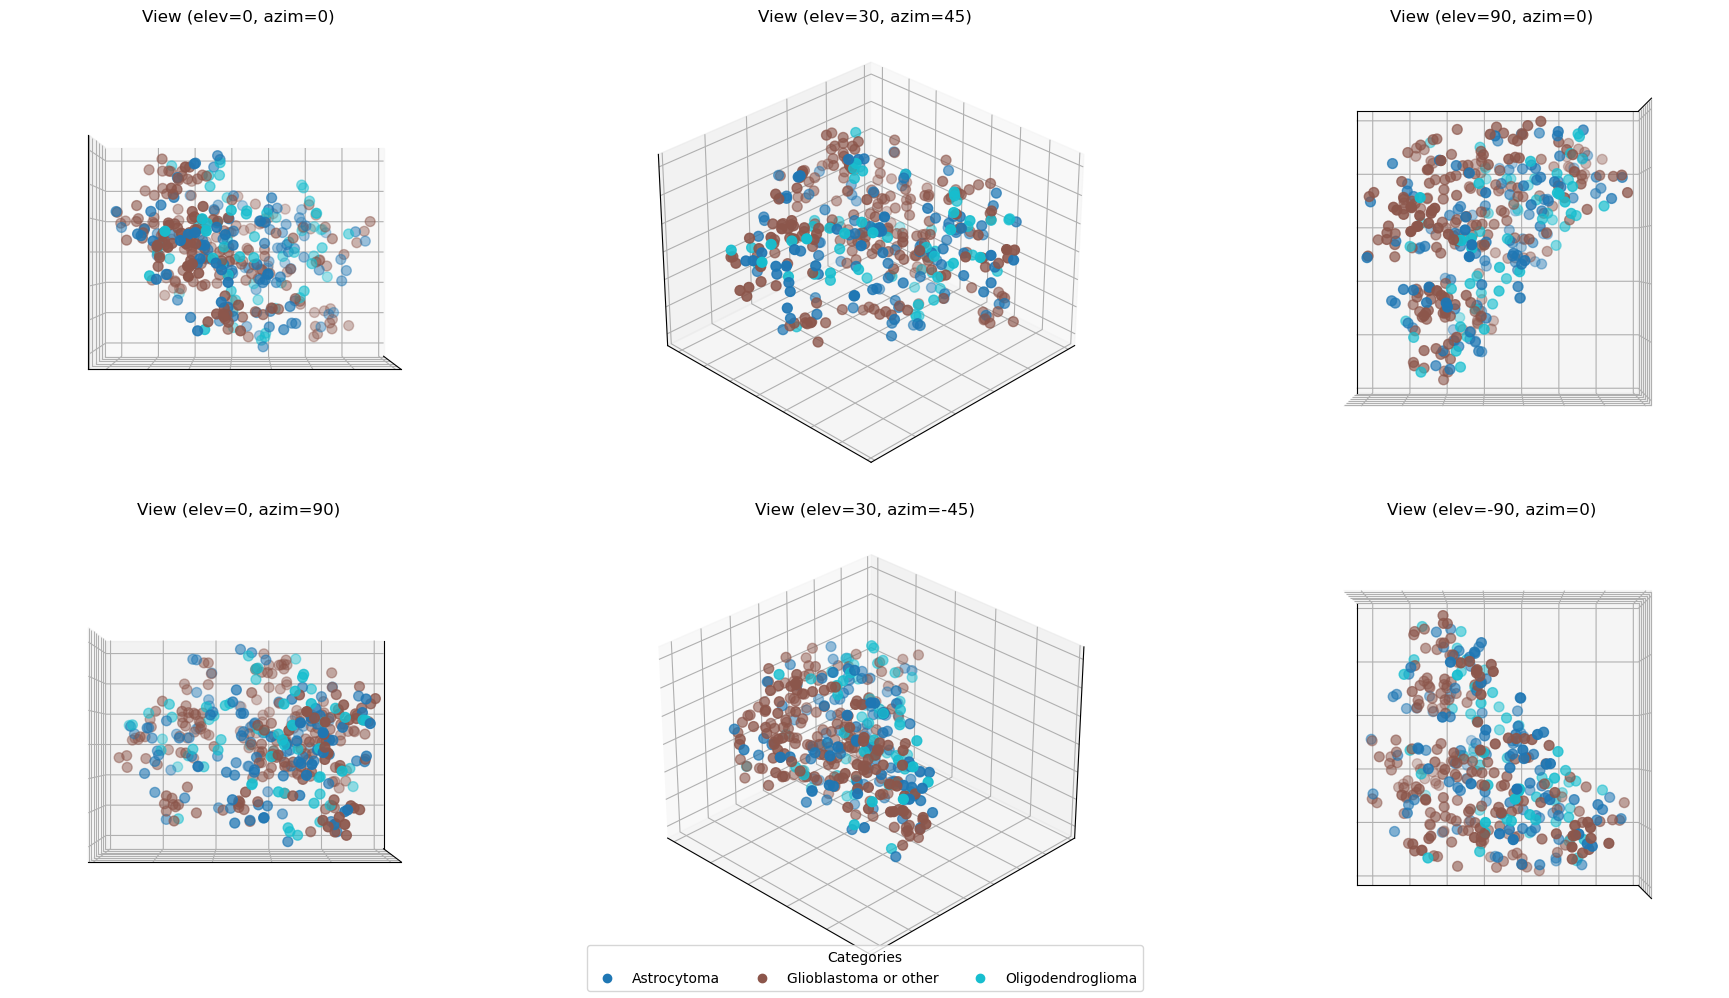

In [12]:
target=class_train_idh
# tumor -> class -> more than 2
title="t-SNE over IDH x-data, labeled by tumor classification"
print(title)
t_sne_plots(x_embedded_idh, target, tumor_categories, tumor_combination_mapping, hidden_classes=['Unknown'], title=None)

In [ ]:
target=y_train_idh
title="t-SNE over IDH x-data, labeled by IDH status"
print(title)
t_sne_plots(x_embedded_idh, target, idh_categories, binary_combination_mapping, hidden_classes=['Unknown'], title=None)

t-SNE over IDH x-data, labeled by Grade


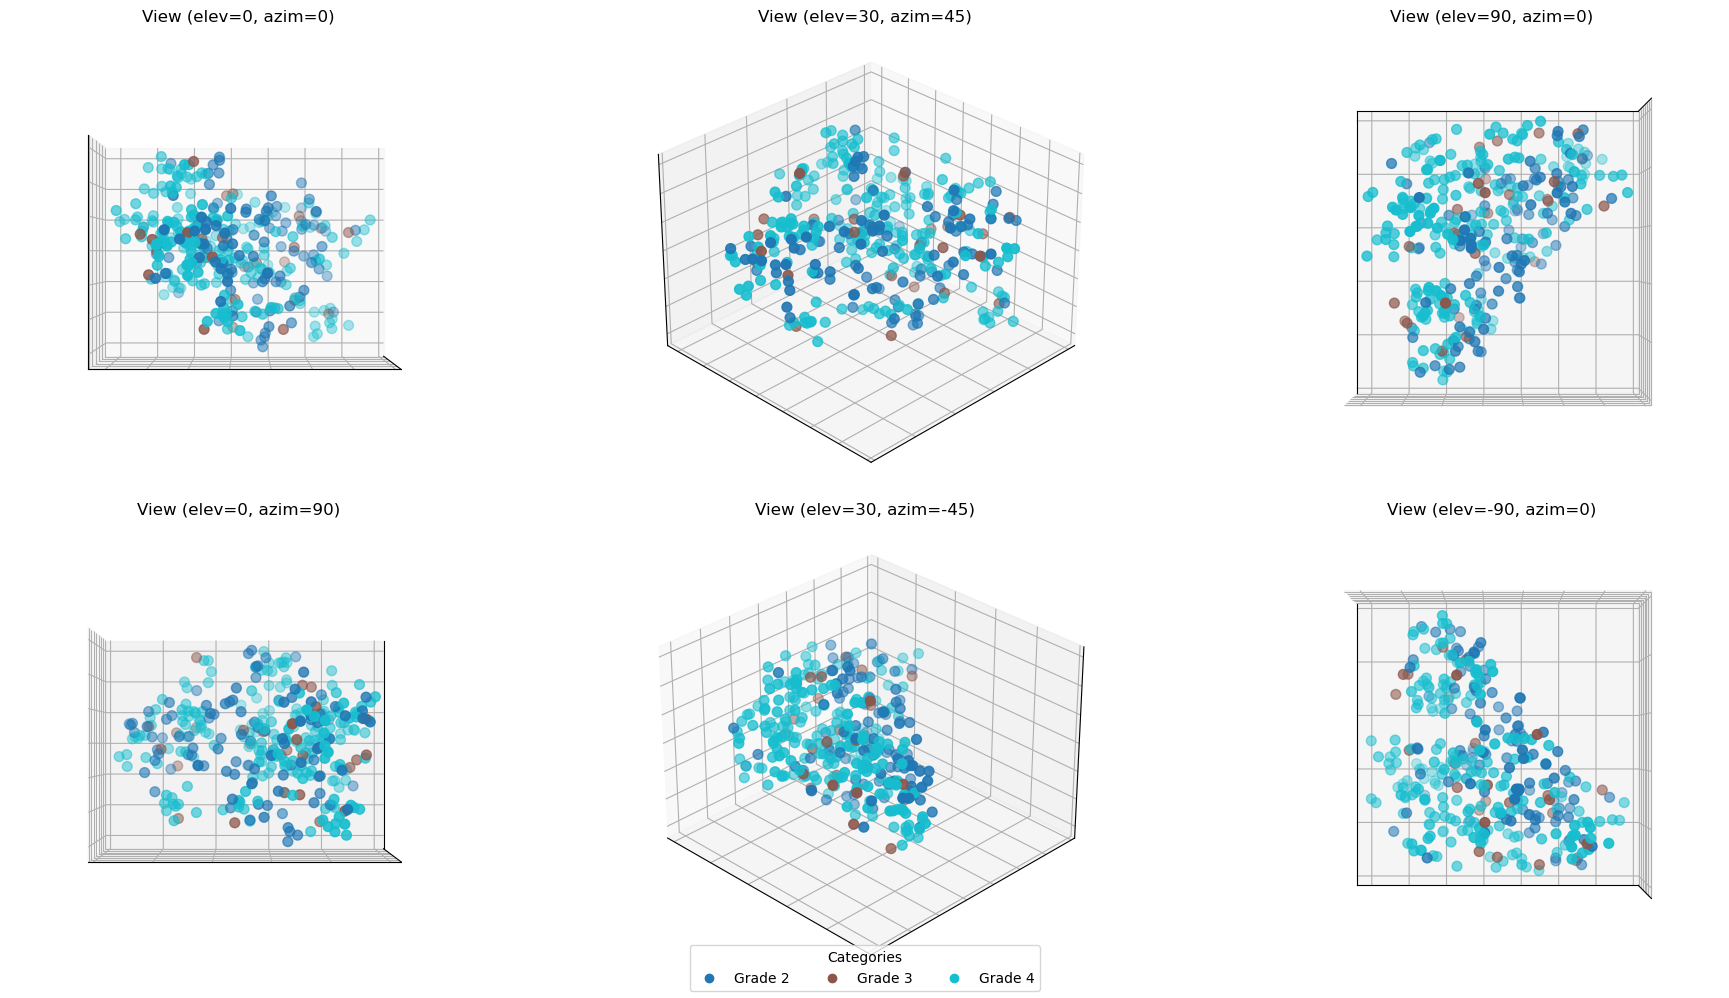

In [13]:
target=grade_train_idh
title="t-SNE over IDH x-data, labeled by Grade"
print(title)
t_sne_plots(x_embedded_idh, target, grade_categories, grade_combination_mapping, hidden_classes=[-1], title=None)

#### 1p19q

In [ ]:
# Initialize t-SNE for 3D embedding
tsne = TSNE(n_components=3, random_state=RANDOM_STATE)

x_embedded_label = tsne.fit_transform(x_train_label)

In [ ]:
target=class_train_label
# tumor -> class -> more than 2
title="t-SNE over 1p19q x-data, labeled by tumor classification"
print(title)
t_sne_plots(x_embedded_label, target, tumor_categories, tumor_combination_mapping, hidden_classes=['Unknown'], title=None)

In [ ]:
target=y_train_label
title="t-SNE over 1p19q x-data, labeled by 1p19q status"
print(title)
t_sne_plots(x_embedded_label, target, label_categories, binary_combination_mapping, hidden_classes=['Unknown'], title=None)

In [ ]:
target=grade_train_label
title="t-SNE over 1p19q x-data, labeled by grade"
print(title)
t_sne_plots(x_embedded_label, target, grade_categories, grade_combination_mapping, hidden_classes=[-1], title=None)

# Enhanced preprocessing pipeline

The following classes are used for the ANFIS and BN pipelines below.

In [38]:



def compute_scale_pos_weight(y):
    n_pos = float((y == 1).sum())
    n_neg = float((y == 0).sum())
    return (n_neg / max(n_pos, 1.0)) if n_pos > 0 else 1.0

    


def _compute_threshold_metrics(y_true, y_proba, thr=0.50):
    y_pred = (y_proba >= thr).astype(int)

    # confusion matrix -> specificity
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0,1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

    return {
        "acc": accuracy_score(y_true, y_pred),
        "prec": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "spec": specificity,
        "bal_acc": balanced_accuracy_score(y_true, y_pred),
        "brier": brier_score_loss(y_true, y_proba),
        # log loss sometimes useful; guarded against 0/1 probs
        "logloss": log_loss(y_true, np.clip(y_proba, 1e-7, 1-1e-7)),
    }


In [39]:
class UniqueThenTopK(BaseEstimator, TransformerMixin):
    """
    1) Score all features (ANOVA by default).
    2) Collapse contrasts FIRST: for each base_id (name without first token), keep best-contrast.
    3) Then top-k per group.
    4) ALWAYS KEEP any columns listed in `always_keep` or matching `always_keep_regex`.
       These bypass uniqueness and top-k and are appended to the final set.

    Assumes names like {contrast}_{...}. 'class' inferred (case-insensitive) from tokens:
    {FirstOrder, Shape, GLCM, GLRLM, GLSZM, GLDM, NGTDM}. Non-matching → 'UNK'.
    Constant features get score 0 (silent).
    """

    CLASS_SET = {"firstorder","shape","glcm","glrlm","glszm","gldm","ngtdm"}

    def __init__(self, k_per_group=10, groupby="class", score_func=f_classif,
                 max_total=None, always_keep=None, always_keep_regex=None):
        self.k_per_group = k_per_group
        self.groupby = groupby
        self.score_func = score_func
        self.max_total = max_total
        self.always_keep = set(always_keep) if always_keep is not None else set()
        self.always_keep_regex = re.compile(always_keep_regex) if isinstance(always_keep_regex, str) else None

    # ----------------- helpers -----------------
    def _parse_meta(self, columns):
        cols = [str(c) for c in columns]
        rows = []
        for name in cols:
            if "_" in name:
                contrast, rest = name.split("_", 1)
            else:
                contrast, rest = "UNK", name
            tokens = rest.split("_")
            cls = "UNK"
            for t in tokens:
                if t.lower() in self.CLASS_SET:
                    cls = t  # keep original casing
                    break
            rows.append({
                "name": name,
                "contrast": contrast,
                "base_id": rest,    # everything after contrast
                "cls": cls,
            })
        return pd.DataFrame(rows)

    def _safe_scores(self, X, y):
        var = np.nanstd(X, axis=0)
        nonconst = var > 0
        scores = np.zeros(X.shape[1], dtype=float)
        if nonconst.any():
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                out = self.score_func(X[:, nonconst], y)
            s = out[0] if isinstance(out, (tuple, list)) else out
            s = np.asarray(s, dtype=float)
            scores[nonconst] = np.nan_to_num(s, nan=0.0, posinf=0.0, neginf=0.0)
        return scores

    def _always_keep_mask(self, columns):
        cols = [str(c) for c in columns]
        mask = np.array([c in self.always_keep for c in cols], dtype=bool)
        if self.always_keep_regex is not None:
            mask = mask | np.array([bool(self.always_keep_regex.search(c)) for c in cols], dtype=bool)
        return mask

    # ----------------- sklearn API -----------------
    def fit(self, X, y):
        if not isinstance(X, pd.DataFrame):
            X = pd.DataFrame(X)
        self.columns_ = list(X.columns)

        # Identify always-keep columns up-front
        ak_mask = self._always_keep_mask(self.columns_)
        ak_idx = np.where(ak_mask)[0]
        ak_names = [self.columns_[i] for i in ak_idx]

        # Work on the remaining columns for scoring/selection
        work_cols = [c for i,c in enumerate(self.columns_) if not ak_mask[i]]
        X_work = X[work_cols]
        meta = self._parse_meta(work_cols)

        # Step 1: score all remaining
        scores_all = self._safe_scores(X_work.values, y)
        meta["score"] = scores_all

        # Step 2: uniqueness across contrasts FIRST
        keep_idx_unique = []
        for base_id, sub in meta.groupby("base_id"):
            j = sub["score"].values.argmax()
            keep_idx_unique.append(sub.index[j])
        uniq_mask = np.zeros(len(meta), dtype=bool)
        uniq_mask[np.asarray(keep_idx_unique, dtype=int)] = True

        # Step 3: group after uniqueness, then top-k per group
        meta_u = meta.loc[uniq_mask].copy()
        if self.groupby == "class":
            meta_u["group"] = meta_u["cls"]
        elif self.groupby == "contrast":
            meta_u["group"] = meta_u["contrast"]
        elif self.groupby == "class_contrast":
            meta_u["group"] = meta_u["cls"] + "|" + meta_u["contrast"]
        else:
            raise ValueError("groupby must be one of {'class','contrast','class_contrast'}")

        keep_idx_topk = []
        for _, sub in meta_u.groupby("group"):
            k = min(self.k_per_group, len(sub))
            keep_idx_topk.extend(sub["score"].nlargest(k).index.tolist())

        # Final mask over working columns
        final_work_mask = np.zeros(len(meta), dtype=bool)
        final_work_mask[np.asarray(keep_idx_topk, dtype=int)] = True

        # Optional global cap after top-k
        if self.max_total is not None and final_work_mask.sum() + len(ak_idx) > self.max_total:
            candidates = meta.loc[final_work_mask]
            keep_global = candidates["score"].nlargest(self.max_total - len(ak_idx)).index
            final_work_mask[:] = False
            final_work_mask[np.asarray(keep_global, dtype=int)] = True

        # Build final selection mask over ALL columns
        final_mask = np.zeros(len(self.columns_), dtype=bool)
        # mark always-keep
        final_mask[ak_idx] = True
        # mark selected from working set
        work_idx_map = {c:i for i,c in enumerate(work_cols)}
        for i, c in enumerate(work_cols):
            if final_work_mask[work_idx_map[c]]:
                final_mask[self.columns_.index(c)] = True

        # Save
        self.meta_ = meta  # metadata for working cols
        self.selected_mask_ = final_mask
        self.selected_features_ = list(pd.Series(self.columns_)[final_mask])

        # For inspection: a frame over all columns
        sel_flags = pd.Series(final_mask, index=self.columns_, name="selected")
        ak_flags  = pd.Series(ak_mask, index=self.columns_, name="always_keep")
        self.selection_frame_ = pd.concat([sel_flags, ak_flags], axis=1)

        return self

    def transform(self, X):
        if not isinstance(X, pd.DataFrame):
            X = pd.DataFrame(X)
        return X.loc[:, self.selected_features_]

    def get_support(self, indices=False):
        if indices:
            return np.where(self.selected_mask_)[0]
        return self.selected_mask_

In [40]:
class GroupedCoeThrLassoSelector(BaseEstimator, TransformerMixin):
    """
    Apply Coe-Thr-Lasso feature selection *within each group of features*.
    Groups are defined by `groupby`: {"class", "contrast", "class_contrast"}.
    """

    CLASS_SET = {"firstorder","shape","glcm","glrlm","glszm","gldm","ngtdm"}

    def __init__(self, alpha_grid=None, random_state=42, test_size=0.5,
                 max_iter=5000, groupby="class", k_per_group=None,
                 always_keep=None, always_keep_regex=None):

        self.alpha_grid = alpha_grid if alpha_grid is not None else np.logspace(-3, 0, 50)
        self.random_state = random_state
        self.test_size = test_size
        self.max_iter = max_iter
        self.groupby = groupby
        self.k_per_group = k_per_group

        self.always_keep = set(always_keep) if always_keep is not None else set()
        self.always_keep_regex = re.compile(always_keep_regex) if isinstance(always_keep_regex, str) else None


    # ---------- helpers ----------

    def _always_keep_mask(self, columns):
        cols = [str(c) for c in columns]

        mask = np.array([c in self.always_keep for c in cols], dtype=bool)

        if self.always_keep_regex is not None:
            mask = mask | np.array(
                [bool(self.always_keep_regex.search(c)) for c in cols],
                dtype=bool
            )

        return mask


    def _parse_meta(self, columns):
        cols = [str(c) for c in columns]

        rows = []
        for name in cols:

            if "_" in name:
                contrast, rest = name.split("_", 1)
            else:
                contrast, rest = "UNK", name

            tokens = rest.split("_")

            cls = "UNK"
            for t in tokens:
                if t.lower() in self.CLASS_SET:
                    cls = t
                    break

            rows.append({
                "name": name,
                "contrast": contrast,
                "base_id": rest,
                "cls": cls,
            })

        meta = pd.DataFrame(rows)

        if self.groupby == "class":
            meta["group"] = meta["cls"]

        elif self.groupby == "contrast":
            meta["group"] = meta["contrast"]

        elif self.groupby == "class_contrast":
            meta["group"] = meta["cls"] + "|" + meta["contrast"]

        else:
            meta["group"] = "all"

        return meta


    def _coe_thr_lasso(self, Xg, y):
        """Run Coe-Thr-Lasso on one group."""

        var_mask = Xg.var(axis=0) > 0
        if not var_mask.any():
            return np.zeros(Xg.shape[1], dtype=bool), np.zeros(Xg.shape[1])

        X1 = Xg.loc[:, var_mask]

        F, p = f_classif(X1.values, y)
        sig_mask = p < 0.05

        if not sig_mask.any():
            return np.zeros(Xg.shape[1], dtype=bool), np.zeros(Xg.shape[1])

        X2 = X1.loc[:, sig_mask]

        lcv = LassoCV(
            alphas=self.alpha_grid,
            cv=5,
            random_state=self.random_state,
            max_iter=self.max_iter
        ).fit(X2.values, y)

        alpha_opt = lcv.alpha_

        lasso = Lasso(
            alpha=alpha_opt,
            random_state=self.random_state,
            max_iter=self.max_iter
        ).fit(X2.values, y)

        coefs = lasso.coef_
        coef_mask = coefs != 0

        if not coef_mask.any():
            return np.zeros(Xg.shape[1], dtype=bool), np.zeros(Xg.shape[1])

        X3 = X2.loc[:, coef_mask]
        coefs3 = coefs[coef_mask]

        hmax, hmin = np.max(np.abs(coefs3)), np.min(np.abs(coefs3))

        X_tr, X_val, y_tr, y_val = train_test_split(
            X3.values, y,
            test_size=self.test_size,
            random_state=self.random_state,
            stratify=y
        )

        best_thr, best_mse = None, np.inf

        for thr in np.arange(hmin, hmax, 0.001):

            mask = np.abs(coefs3) > thr
            if not mask.any():
                continue

            X_thr = X_tr[:, mask]
            X_val_thr = X_val[:, mask]

            m = Lasso(
                alpha=alpha_opt,
                random_state=self.random_state,
                max_iter=self.max_iter
            ).fit(X_thr, y_tr)

            mse = np.mean((m.predict(X_val_thr) - y_val) ** 2)

            if mse < best_mse:
                best_mse = mse
                best_thr = thr

        final_thr = best_thr if best_thr is not None else hmin
        final_mask_local = np.abs(coefs3) > final_thr

        selected_cols = set(X3.columns[final_mask_local])

        sel_mask = np.array([c in selected_cols for c in Xg.columns])

        scores = np.zeros(Xg.shape[1])
        scores[sel_mask] = np.abs(coefs3[final_mask_local])

        return sel_mask, scores


    # ---------- sklearn API ----------

    def fit(self, X, y):

        if not isinstance(X, pd.DataFrame):
            X = pd.DataFrame(X)

        self.columns_ = list(X.columns)

        # always keep mask
        ak_mask = self._always_keep_mask(self.columns_)
        ak_idx = np.where(ak_mask)[0]

        # working features
        work_cols = [c for i, c in enumerate(self.columns_) if not ak_mask[i]]
        X_work = X[work_cols]

        meta = self._parse_meta(work_cols)

        sel_mask_work = np.zeros(len(work_cols), dtype=bool)
        scores_all = np.zeros(len(work_cols))

        for g, idx in meta.groupby("group").groups.items():

            idx = list(idx)

            cols = [work_cols[i] for i in idx]
            Xg = X_work[cols]

            sel_local, scores_local = self._coe_thr_lasso(Xg, y)

            sel_mask_work[idx] = sel_local
            scores_all[idx] = scores_local

            if self.k_per_group is not None and sel_local.sum() > self.k_per_group:

                top_idx = np.argsort(-scores_local)[:self.k_per_group]

                sel_mask_work[idx] = False
                sel_mask_work[np.array(idx)[top_idx]] = True


        # final mask over ALL columns
        final_mask = np.zeros(len(self.columns_), dtype=bool)

        # always keep
        final_mask[ak_idx] = True

        # selected working features
        for i, c in enumerate(work_cols):
            if sel_mask_work[i]:
                final_mask[self.columns_.index(c)] = True


        self.selected_mask_ = final_mask
        self.selected_features_ = list(pd.Series(self.columns_)[final_mask])

        # metadata (only working features)
        meta["score"] = scores_all
        meta["selected"] = sel_mask_work
        self.meta_ = meta

        return self


    def transform(self, X):

        if not isinstance(X, pd.DataFrame):
            X = pd.DataFrame(X)

        return X.loc[:, self.selected_features_]


    def get_support(self, indices=False):

        if indices:
            return np.where(self.selected_mask_)[0]

        return self.selected_mask_


In [41]:
class UniqueThenTopKLasso(BaseEstimator, TransformerMixin):

    CLASS_SET = {"firstorder","shape","glcm","glrlm","glszm","gldm","ngtdm"}

    def __init__(
        self,
        k_per_group=10,
        groupby="class",
        score_func=f_classif,
        anova_top_n=2000,
        alpha_grid=None,
        lasso_max_iter=10000,
        random_state=42,
        always_keep=None,
        always_keep_regex=None,
    ):

        self.k_per_group = k_per_group
        self.groupby = groupby
        self.score_func = score_func
        self.anova_top_n = anova_top_n
        self.alpha_grid = alpha_grid if alpha_grid is not None else np.logspace(-3,1,50)
        self.lasso_max_iter = lasso_max_iter
        self.random_state = random_state

        self.always_keep = set(always_keep) if always_keep is not None else set()
        self.always_keep_regex = re.compile(always_keep_regex) if isinstance(always_keep_regex,str) else None


    # ---------- helpers ----------

    def _always_keep_mask(self, columns):

        cols = [str(c) for c in columns]

        mask = np.array([c in self.always_keep for c in cols], dtype=bool)

        if self.always_keep_regex is not None:
            mask |= np.array([bool(self.always_keep_regex.search(c)) for c in cols])

        return mask


    def _parse_meta(self, columns):

        rows = []

        for name in columns:

            if "_" in name:
                contrast, rest = name.split("_",1)
            else:
                contrast, rest = "UNK", name

            tokens = rest.split("_")

            cls="UNK"

            for t in tokens:
                if t.lower() in self.CLASS_SET:
                    cls=t
                    break

            rows.append({
                "name":name,
                "contrast":contrast,
                "base_id":rest,
                "cls":cls
            })

        return pd.DataFrame(rows)


    def _safe_scores(self,X,y):

        var=np.nanstd(X,axis=0)

        nonconst=var>0

        scores=np.zeros(X.shape[1])

        if nonconst.any():

            with warnings.catch_warnings():
                warnings.simplefilter("ignore")

                out=self.score_func(X[:,nonconst],y)

            s=out[0] if isinstance(out,(tuple,list)) else out

            scores[nonconst]=np.nan_to_num(s)

        return scores


    # ---------- sklearn API ----------

    def fit(self,X,y):

        if not isinstance(X,pd.DataFrame):
            X=pd.DataFrame(X)

        self.columns_=list(X.columns)

        ak_mask=self._always_keep_mask(self.columns_)
        ak_idx=np.where(ak_mask)[0]

        work_cols=[c for i,c in enumerate(self.columns_) if not ak_mask[i]]
        X_work=X[work_cols]

        meta=self._parse_meta(work_cols)


        # ---------- STEP 1 ANOVA FILTER ----------

        scores=self._safe_scores(X_work.values,y)

        meta["anova_score"]=scores

        if self.anova_top_n is not None and len(scores)>self.anova_top_n:

            keep=np.argsort(-scores)[:self.anova_top_n]

            meta=meta.iloc[keep]
            X_work=X_work.iloc[:,keep]


        # ---------- STEP 2 COLLAPSE CONTRASTS ----------

        keep_idx=[]

        for base_id,sub in meta.groupby("base_id"):

            j=sub["anova_score"].values.argmax()

            keep_idx.append(sub.index[j])

        meta=meta.loc[keep_idx]

        X_work=X_work[meta["name"]]


        # ---------- STEP 3 LASSO ----------

        scaler=StandardScaler()

        X_scaled=scaler.fit_transform(X_work)

        lcv=LassoCV(
            alphas=self.alpha_grid,
            cv=5,
            random_state=self.random_state,
            max_iter=self.lasso_max_iter
        ).fit(X_scaled,y)

        coefs=lcv.coef_

        meta["lasso_coef"]=np.abs(coefs)


        # ---------- STEP 4 GROUP TOP-K ----------

        if self.groupby=="class":
            meta["group"]=meta["cls"]

        elif self.groupby=="contrast":
            meta["group"]=meta["contrast"]

        elif self.groupby=="class_contrast":
            meta["group"]=meta["cls"]+"|"+meta["contrast"]

        else:
            meta["group"]="all"


        keep=[]

        for _,sub in meta.groupby("group"):

            k=min(self.k_per_group,len(sub))

            keep.extend(
                sub["lasso_coef"].nlargest(k).index.tolist()
            )


        final_names=meta.loc[keep,"name"].tolist()

        final_names+=list(np.array(self.columns_)[ak_idx])


        self.selected_features_=list(dict.fromkeys(final_names))

        self.selected_mask_=np.array(
            [c in self.selected_features_ for c in self.columns_]
        )

        self.meta_=meta

        return self


    def transform(self,X):

        if not isinstance(X,pd.DataFrame):
            X=pd.DataFrame(X)

        return X[self.selected_features_]


    def get_support(self,indices=False):

        if indices:
            return np.where(self.selected_mask_)[0]

        return self.selected_mask_

# ANFIS with Automatic Clustering

Adaptive Neuro-Fuzzy Inference System trained over the SHAP-ranked features from XGBoost.

## Methods

In [25]:
def predict_explain_rules_batch(
    X_pool: pd.DataFrame, *, model, artifacts,
    rows=None,
    rule_weight_thresh: float = 0.15,
    feature_frac_thresh: float = 0.10,
    max_rules: int | None = None,
    max_feats: int | None = 3
) -> pd.DataFrame:
    # --- subset
    if rows is not None:
        try:   X_sel = X_pool.loc[rows]
        except Exception: X_sel = X_pool.iloc[rows]
    else:
        X_sel = X_pool

    # --- re-run your fold preproc
    Xtr_proc, X_proc = pre_proc(
        artifacts["X_train_ref"], artifacts["y_train_ref"], X_sel,
        **artifacts["preproc_kwargs"]
    )

    feat_names = artifacts["feature_names_top"]
    missing = [c for c in feat_names if c not in X_proc.columns]
    if missing:
        raise ValueError(f"Missing expected features after pre_proc: {missing[:8]} ...")

    # project to rule Z-space
    X_top = X_proc.loc[:, feat_names].to_numpy()
    Z = (X_top - artifacts["scaler_mean"]) / np.maximum(artifacts["scaler_scale"], 1e-12)
    idx = X_proc.index
    N, M = Z.shape
    centers = artifacts["centers"]
    K = centers.shape[0]

    # --- probs
    model.eval()
    with torch.no_grad():
        logits = model(torch.tensor(Z, dtype=torch.float32)).cpu().numpy()
        m = logits.max(axis=1, keepdims=True)
        P = np.exp(logits - m) / np.maximum(np.exp(logits - m).sum(axis=1, keepdims=True), 1e-12)
    yhat = P.argmax(axis=1)
    phat = P.max(axis=1)

    # --- rule weights
    if artifacts["mode"] == "diag":
        sig = artifacts["sigmas"]
        diff = Z[:, None, :] - centers[None, :, :]
        s = -0.5 * ((diff / (sig + 1e-12)) ** 2).sum(axis=2)
    else:
        if artifacts.get("cov_type", "diag") == "diag":
            inv = 1.0 / (artifacts["covariances_diag"] + 1e-12)
            diff = Z[:, None, :] - centers[None, :, :]
            s = -0.5 * (diff**2 * inv[None, :, :]).sum(axis=2)
        else:
            covs = artifacts["covariances_full"]
            s = np.empty((N, K), dtype=float)
            for k in range(K):
                Ck = covs[k] + 1e-6*np.eye(M)
                L = np.linalg.cholesky(Ck)
                D = Z - centers[k]
                sol = np.linalg.solve(L, D.T)
                s[:, k] = -0.5 * (sol**2).sum(axis=0)
        if "mixture_weights" in artifacts:
            s += np.log(np.maximum(artifacts["mixture_weights"], 1e-12))[None, :]
    mrow = s.max(axis=1, keepdims=True)
    e = np.exp(s - mrow)
    W = e / np.maximum(e.sum(axis=1, keepdims=True), 1e-12)

    # --- per-feature contribs + tags
    contrib = np.zeros((N, K, M), dtype=float)
    tags = np.empty((N, K, M), dtype=object)

    if artifacts["mode"] == "diag":
        sig = artifacts["sigmas"] + 1e-12
        D = Z[:, None, :] - centers[None, :, :]
        contrib = (D**2) / (sig[None, :, :]**2)
        tags = np.where(D >= 0, "high", "low")
    elif artifacts.get("cov_type", "diag") == "diag":
        var = artifacts["covariances_diag"] + 1e-12
        D = Z[:, None, :] - centers[None, :, :]
        contrib = (D**2) * (1.0 / var[None, :, :])
        tags = np.where(D >= 0, "high", "low")
    else:
        covs = artifacts["covariances_full"]
        for k in range(K):
            D = Z - centers[k]
            Pk = np.linalg.inv(covs[k] + 1e-6*np.eye(M))
            PD = D @ Pk.T
            contrib[:, k, :] = np.abs(D * PD)
            tags[:, k, :] = np.where(D >= 0, "high", "low")

    denom = np.maximum(contrib.sum(axis=2, keepdims=True), 1e-12)
    feat_frac = contrib / denom

    # --- build tidy rows
    rows_out = []
    for i in range(N):
        w_i = W[i]
        rule_order = np.argsort(-w_i)
        keep_rules = [r for r in rule_order if w_i[r] >= rule_weight_thresh] or [int(rule_order[0])]
        if max_rules is not None:
            keep_rules = keep_rules[:max_rules]

        # (IMPORTANT) loop MUST be outside the if-block above
        for r_rank, r in enumerate(keep_rules, start=1):
            frac_r = feat_frac[i, r]
            contrib_r = contrib[i, r]
            tags_r = tags[i, r]

            # choose features to save
            order_j = np.argsort(-frac_r)
            kept_feats = [j for j in order_j if frac_r[j] >= feature_frac_thresh] or [int(order_j[0])]
            if max_feats is not None:
                kept_feats = kept_feats[:max_feats]

            # rule-wide sentence (lists *all* kept features)
            parts_rule = [f"{feat_names[j]} is {tags_r[j]} (frac={frac_r[j]:.2f})" for j in kept_feats]
            sentence_rule = (
                f"Rule #{r} (w={w_i[r]:.2f}) -> " + "; ".join(parts_rule) +
                f" -> class {int(yhat[i])} (P={phat[i]:.2f})."
            )

            # one row per feature with its *own* sentence
            for j in kept_feats:
                sentence_feat = (
                    f"Rule #{r} (w={w_i[r]:.2f}) -> {feat_names[j]} is {tags_r[j]} "
                    f"(frac={frac_r[j]:.2f}) -> class {int(yhat[i])} (P={phat[i]:.2f})."
                )
                rows_out.append({
                    "patient_id": idx[i],
                    "pred": int(yhat[i]),
                    "prob_pred": float(phat[i]),
                    "rule_id": int(r),
                    "rule_weight": float(w_i[r]),
                    "rule_rank": r_rank,
                    "feature": feat_names[j],
                    "tag": tags_r[j],
                    "feat_frac": float(frac_r[j]),
                    "feat_contrib": float(contrib_r[j]),
                    # keep backward-compat: sentence == per-row sentence
                    "sentence": sentence_feat,
                    # add the rule-wide sentence too
                    "sentence_rule": sentence_rule
                })

    report = pd.DataFrame(rows_out).sort_values(
        ["patient_id", "rule_rank", "feat_frac"], ascending=[True, True, False]
    ).reset_index(drop=True)
    return report

def cross_validate_shap_to_anfis(
    X: pd.DataFrame, y, *,
    preproc_kwargs: dict,
    top_k: int = 10,
    xgb_kwargs: dict = None,
    fuzzy_antecedents_method: str = "gaussianmix",  # 'gaussianmix' | 'kmeans'
    elliptical: bool = False,                       # True = Mahalanobis, False = diag
    K_rules: int = 8,
    gmm_cov: str = "auto",                          # 'auto'|'diag'|'full' (GMM)
    n_splits: int = 5,
    epochs: int = 200,
    lr: float = 1e-3,
    wd: float = 1e-4,
    freeze_antecedents_epochs: int = 0,
    seed: int = 0,
    # reporting
    save_reports: bool = True,
    report_dir: str = "anfis_cv_reports",
    rule_weight_thresh: float = 0.15,
    feature_frac_thresh: float = 0.10,
    max_rules: int | None = 3,
    max_feats: int | None = 3
):
    """
    Cross-validation pipeline:
      1) pre_proc on (X_tr, y_tr, X_va)
      2) Train XGBoost on the train fold
      3) Native SHAP → select top_k features (train fold only)
      4) Build fuzzy antecedents (KMeans or GMM) + init consequents
      5) Train zero-order ANFIS on z-space; evaluate on val
      6) Save fold-level reports and final aggregates (locale-friendly CSVs)

    Requires:
      - pre_proc(...) provided by caller
      - predict_explain_rules_batch(...) available in scope (used for local explanations)
    """
    import pathlib, json
    from sklearn.model_selection import StratifiedKFold
    from sklearn.preprocessing import StandardScaler
    from sklearn.mixture import GaussianMixture
    from sklearn.cluster import KMeans
    from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix
    from threadpoolctl import threadpool_limits
    from tqdm.auto import trange
    import torch, torch.nn as nn
    import numpy as np, pandas as pd, xgboost as xgb

    # ---- Locale-friendly CSV kwargs (apply to every to_csv) ----
    CSV_KW = dict(index=False, sep=';', decimal=',', float_format='%.6f')

    assert isinstance(X, pd.DataFrame), "X must be a DataFrame with named columns."
    y = np.asarray(y, int)
    C = int(y.max()) + 1
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)

    if xgb_kwargs is None:
        xgb_kwargs = dict(
            n_estimators=3000, max_depth=4, learning_rate=0.03,
            subsample=0.8, colsample_bytree=0.6, reg_lambda=1.0,
            tree_method="hist", n_jobs=-1, random_state=seed,
            objective=("binary:logistic" if C == 2 else "multi:softprob"),
            eval_metric=("logloss" if C == 2 else "mlogloss"),
            num_class=(None if C == 2 else C),
        )

    out_root = pathlib.Path(report_dir)
    if save_reports:
        out_root.mkdir(parents=True, exist_ok=True)
    all_local, all_rules, all_rulebook, all_features = [], [], [], []
    aucs, accs, recs, specs = [], [], [], []

    for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), 1):
        Xtr_raw, Xva_raw = X.iloc[tr_idx], X.iloc[va_idx]
        ytr, yva = y[tr_idx], y[va_idx]

        # ---------- 1) pre-process THIS FOLD ----------
        Xtr_proc, Xva_proc = pre_proc(Xtr_raw, ytr, Xva_raw, **preproc_kwargs)
        if not isinstance(Xtr_proc, pd.DataFrame) or not isinstance(Xva_proc, pd.DataFrame):
            raise TypeError("pre_proc must return pandas DataFrames.")

        # ---------- 2) train XGB on train fold (with class weights) ----------
        counts = np.bincount(ytr, minlength=C)
        weights = len(ytr) / (C * np.maximum(counts, 1))
        w_tr = weights[ytr]

        xgb_model = xgb.XGBClassifier(**xgb_kwargs)
        xgb_model.fit(Xtr_proc, ytr, sample_weight=w_tr, eval_set=[(Xva_proc, yva)], verbose=False)
        booster = xgb_model.get_booster()
        booster.feature_names = list(Xtr_proc.columns)

        # ---------- 3) Native SHAP on train → top-k names ----------
        dtr = xgb.DMatrix(Xtr_proc, label=ytr)
        contribs_tr = booster.predict(dtr, pred_contribs=True, approx_contribs=False)
        phi_tr = contribs_tr[:, :-1]  # drop bias term
        feat_names = dtr.feature_names or booster.feature_names
        mean_abs_phi = np.mean(np.abs(phi_tr), axis=0)

        order = np.argsort(mean_abs_phi)[::-1]
        top = order[:min(top_k, phi_tr.shape[1])]
        top_names_list = [feat_names[i] for i in top]

        # (optional) save ALL features with selection flag
        if save_reports:
            fold_dir = out_root / f"fold_{fold}"
            fold_dir.mkdir(parents=True, exist_ok=True)
            rank_all = np.empty_like(order); rank_all[order] = np.arange(1, len(order)+1)
            df_feat = pd.DataFrame({
                "fold": fold,
                "feature": feat_names,
                "abs_phi": mean_abs_phi,
                "rank_all": rank_all,
                "selected": False,
                "selected_rank": np.nan
            })
            sel_mask = np.zeros(len(feat_names), dtype=bool); sel_mask[top] = True
            df_feat.loc[sel_mask, "selected"] = True
            df_feat.loc[sel_mask, "selected_rank"] = df_feat.loc[sel_mask, "rank_all"]
            df_feat.sort_values(["selected", "rank_all"], ascending=[False, True], inplace=True)
            df_feat.to_csv(fold_dir / "feature_selection.csv", **CSV_KW)
            all_features.append(df_feat)

        # ---------- 4) Build rules + init consequents ----------
        scaler = StandardScaler().fit(Xtr_proc.loc[:, top_names_list].to_numpy())
        Ztr = scaler.transform(Xtr_proc.loc[:, top_names_list].to_numpy())
        Zva = scaler.transform(Xva_proc.loc[:, top_names_list].to_numpy())
        sel_names = list(top_names_list)

        # drop near-constant cols
        col_std = Ztr.std(axis=0)
        if np.any(col_std < 1e-12):
            keep = np.where(col_std >= 1e-12)[0]
            if keep.size == 0:
                raise ValueError("All selected features are near-constant after scaling.")
            Ztr, Zva = Ztr[:, keep], Zva[:, keep]
            sel_names = [sel_names[i] for i in keep]
        M = Ztr.shape[1]

        with threadpool_limits(1):  # keep BLAS threads in check for clustering
            if fuzzy_antecedents_method == "kmeans":
                n_unique = np.unique(Ztr, axis=0).shape[0]
                K = max(1, min(K_rules, n_unique))
                km = KMeans(n_clusters=K, n_init=20, random_state=seed).fit(Ztr)
                centers = km.cluster_centers_
                sigmas = np.vstack([
                    np.maximum((Ztr[km.labels_ == k].std(axis=0) if (km.labels_ == k).any()
                                else Ztr.std(axis=0)), 1e-3)
                    for k in range(K)
                ])
                covariances, cov_type, mix_weights = None, "diag", None
            else:
                cov_type = ("full" if (gmm_cov == "auto" and M <= 12) else
                            "diag" if (gmm_cov == "auto") else gmm_cov)
                gmm = GaussianMixture(
                    n_components=K_rules, covariance_type=cov_type,
                    n_init=5, reg_covar=1e-6, random_state=seed
                ).fit(Ztr)
                K = gmm.n_components
                centers = gmm.means_.copy()
                mix_weights = gmm.weights_.copy()
                if cov_type == "diag":
                    covariances = gmm.covariances_.copy()   # (K,M) variances
                    sigmas = np.sqrt(covariances)           # (K,M) stds
                else:
                    covariances = gmm.covariances_.copy()   # (K,M,M)
                    sigmas = np.sqrt(np.stack([np.diag(C) for C in covariances], 0))

        # compute Wtr to init consequents
        if elliptical:
            if cov_type == "diag":
                inv = 1.0 / (covariances if isinstance(covariances, np.ndarray) and covariances.ndim == 2 else (sigmas**2))
                diff = Ztr[:, None, :] - centers[None, :, :]
                md2 = (diff**2 * inv[None, :, :]).sum(axis=2)
            else:
                Ntr = Ztr.shape[0]
                md2 = np.empty((Ntr, K), dtype=float)
                for k in range(K):
                    Ck = covariances[k] + 1e-6*np.eye(M)
                    L = np.linalg.cholesky(Ck)
                    sol = np.linalg.solve(L, (Ztr - centers[k]).T)
                    md2[:, k] = (sol**2).sum(axis=0)
            s = -0.5 * np.minimum(md2, 700.0)
            if mix_weights is not None:
                s += np.log(np.maximum(mix_weights, 1e-12))[None, :]
        else:
            diff = Ztr[:, None, :] - centers[None, :, :]
            s = -0.5 * ((diff / (sigmas + 1e-12)) ** 2).sum(axis=2)
        mrow = s.max(axis=1, keepdims=True)
        Wtr = np.exp(s - mrow); Wtr = Wtr / np.maximum(Wtr.sum(axis=1, keepdims=True), 1e-12)

        # zero-order consequents from weighted class proportions
        B = np.zeros((K, C))
        for k in range(K):
            wk = Wtr[:, k]; den = wk.sum() + 1e-8
            for c in range(C):
                B[k, c] = (wk * (ytr == c)).sum() / den
        consequents = np.log(B + 1e-6)

        # ---------- 5) Train ANFIS ----------
        class ANFISZeroOrder(nn.Module):
            def __init__(self, centers, sigmas, consequents):
                super().__init__()
                self.centers = nn.Parameter(torch.tensor(centers, dtype=torch.float32))
                self.log_sigma = nn.Parameter(torch.log(torch.tensor(sigmas, dtype=torch.float32)))
                self.consequents = nn.Parameter(torch.tensor(consequents, dtype=torch.float32))
            def forward(self, x):
                sigma = torch.exp(self.log_sigma)
                diff = x[:, None, :] - self.centers[None, :, :]
                s = -0.5 * ((diff / sigma) ** 2).sum(-1)
                w = torch.softmax(s, dim=1)
                return w @ self.consequents

        class ANFISZeroOrderElliptical(nn.Module):
            def __init__(self, centers, consequents, cov_type, cov_diag=None, cov_full=None, mixture_weights=None):
                super().__init__()
                K_, M_ = centers.shape
                self.cov_type = cov_type
                self.centers = nn.Parameter(torch.tensor(centers, dtype=torch.float32))
                self.consequents = nn.Parameter(torch.tensor(consequents, dtype=torch.float32))
                if cov_type == "diag":
                    inv_diag = 1.0 / (cov_diag + 1e-12)
                    self.register_buffer("inv_diag", torch.tensor(inv_diag, dtype=torch.float32))
                else:
                    inv_full = []
                    for k in range(K_):
                        Ck = cov_full[k] + 1e-6 * np.eye(M_)
                        inv_full.append(np.linalg.inv(Ck))
                    self.register_buffer("inv_full", torch.tensor(np.stack(inv_full, 0), dtype=torch.float32))
                self.register_buffer("mix_weights", torch.tensor(mixture_weights, dtype=torch.float32) if mixture_weights is not None else None)
            def forward(self, x):
                diff = x[:, None, :] - self.centers[None, :, :]
                if self.cov_type == "diag":
                    md2 = (diff**2 * self.inv_diag[None, :, :]).sum(-1)
                else:
                    md2 = torch.einsum('bkm,kmn,bkn->bk', diff, self.inv_full, diff)
                s = -0.5 * md2
                if self.mix_weights is not None:
                    s = s + torch.log(self.mix_weights + 1e-12)
                w = torch.softmax(s, dim=1)
                return w @ self.consequents

        if not elliptical:
            model = ANFISZeroOrder(centers=np.array(centers), sigmas=np.array(sigmas), consequents=np.array(consequents))
        else:
            if cov_type == "diag":
                model = ANFISZeroOrderElliptical(
                    centers=np.array(centers), consequents=np.array(consequents),
                    cov_type="diag",
                    cov_diag=(covariances if isinstance(covariances, np.ndarray) and covariances.ndim==2 else (sigmas**2)),
                    mixture_weights=mix_weights
                )
            else:
                model = ANFISZeroOrderElliptical(
                    centers=np.array(centers), consequents=np.array(consequents),
                    cov_type="full", cov_full=np.array(covariances),
                    mixture_weights=mix_weights
                )

        opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
        crit = nn.CrossEntropyLoss()

        Xtr_t = torch.tensor(Ztr, dtype=torch.float32)
        ytr_t = torch.tensor(ytr, dtype=torch.long)
        Xva_t = torch.tensor(Zva, dtype=torch.float32)
        yva_t = torch.tensor(yva, dtype=torch.long)

        # optional warm-up (only consequents)
        if freeze_antecedents_epochs > 0:
            opt1 = torch.optim.Adam([{"params": model.consequents, "lr": lr}], weight_decay=wd)
            for _ in trange(freeze_antecedents_epochs, desc=f"Fold {fold} (freeze)", leave=False):
                model.train(); opt1.zero_grad()
                loss = crit(model(Xtr_t), ytr_t)
                loss.backward(); opt1.step()

        # full fine-tune
        for _ in trange(epochs, desc=f"Fold {fold}", leave=False):
            model.train(); opt.zero_grad()
            loss = crit(model(Xtr_t), ytr_t)
            reg = 1e-4 * (sum(p.pow(2).mean() for n, p in model.named_parameters() if 'consequents' not in n))
            (loss + reg).backward(); opt.step()

        # ---------- eval on validation ----------
        model.eval()
        with torch.no_grad():
            probs = torch.softmax(model(Xva_t), dim=1).cpu().numpy()
            preds = probs.argmax(1)

        acc = accuracy_score(yva, preds)
        auc = roc_auc_score(yva, probs[:,1]) if C == 2 else roc_auc_score(yva, probs, multi_class="ovr")

        # Recall/Sensitivity & Specificity
        cm = confusion_matrix(yva, preds, labels=np.arange(C))
        if C == 2:
            pos_label = 1 if (1 in np.unique(y)) else (C - 1)
            tp = cm[pos_label, pos_label]
            fn = cm[pos_label, :].sum() - tp
            fp = cm[:, pos_label].sum() - tp
            tn = cm.sum() - tp - fn - fp
            rec = tp / max(tp + fn, 1e-12)
            spec = tn / max(tn + fp, 1e-12)
        else:
            tp = np.diag(cm)
            fn = cm.sum(axis=1) - tp
            fp = cm.sum(axis=0) - tp
            tn = cm.sum() - (tp + fn + fp)
            rec = np.nanmean(tp / np.maximum(tp + fn, 1e-12))   # macro recall
            spec = np.nanmean(tn / np.maximum(tn + fp, 1e-12))  # macro specificity

        aucs.append(auc); accs.append(acc); recs.append(rec); specs.append(spec)
        print(f"[Fold {fold}] AUC={auc:.3f}  Acc={acc:.3f}  Rec/Sens={rec:.3f}  Spec={spec:.3f}")

        # ---------- per-fold reports ----------
        if save_reports:
            fold_dir = out_root / f"fold_{fold}"
            fold_dir.mkdir(parents=True, exist_ok=True)

            # artifacts used to re-preproc val and create local explanations
            artifacts = {
                "X_train_ref": Xtr_raw.copy(),
                "y_train_ref": pd.Series(ytr, index=Xtr_raw.index),
                "preproc_kwargs": preproc_kwargs,
                "feature_names_top": sel_names,
                "scaler_mean": scaler.mean_,
                "scaler_scale": scaler.scale_,
                "centers": centers,
                "consequents": consequents,
                "mode": ("elliptical" if elliptical else "diag"),
            }
            if not elliptical:
                artifacts["sigmas"] = sigmas
            else:
                artifacts["cov_type"] = cov_type
                if cov_type == "diag":
                    artifacts["covariances_diag"] = (covariances if isinstance(covariances, np.ndarray) and covariances.ndim==2 else (sigmas**2))
                else:
                    artifacts["covariances_full"] = covariances
                if mix_weights is not None:
                    artifacts["mixture_weights"] = mix_weights

            # Per-patient feature-level CSV (validation fold)
            df_local = predict_explain_rules_batch(
                X_pool=Xva_raw, model=model, artifacts=artifacts,
                rows=None,
                rule_weight_thresh=rule_weight_thresh,
                feature_frac_thresh=feature_frac_thresh,
                max_rules=max_rules, max_feats=max_feats
            )
            # attach y_true aligned to the post-preproc index
            try:
                y_add = pd.Series(yva, index=Xva_raw.index).loc[df_local["patient_id"]].to_numpy()
            except Exception:
                y_add = yva[df_local["patient_id"].astype(int)]
            df_local.insert(df_local.columns.get_loc("pred"), "y_true", y_add)
            df_local.insert(0, "fold", fold)
            df_local.to_csv(fold_dir / "anfis_local_explanations.csv", **CSV_KW)
            all_local.append(df_local)

            # Rule-level CSV (one row per (patient, rule))
            rules_df = (
                df_local[df_local["sentence"] != ""]
                .loc[:, ["fold","patient_id","y_true","pred","prob_pred","rule_id","rule_rank","rule_weight","sentence"]]
                .sort_values(["fold","patient_id","rule_rank"])
                .reset_index(drop=True)
            )
            rules_df.to_csv(fold_dir / "anfis_local_rules.csv", **CSV_KW)
            all_rules.append(rules_df)

            # Rulebook for this fold (no patients)
            Kf = artifacts["centers"].shape[0]
            feat_names_rb = artifacts["feature_names_top"]
            centers_z = artifacts["centers"]
            sc_mean = artifacts["scaler_mean"]; sc_scale = artifacts["scaler_scale"]
            conseq = artifacts["consequents"]
            priors = artifacts.get("mixture_weights", np.full(Kf, 1.0 / Kf))

            if artifacts["mode"] == "diag":
                std_km = artifacts["sigmas"]
            elif artifacts.get("cov_type","diag") == "diag":
                std_km = np.sqrt(artifacts["covariances_diag"])
            else:
                covs = artifacts["covariances_full"]
                std_km = np.stack([np.sqrt(np.diag(Ck)) for Ck in covs], axis=0)

            rows_rulebook = []
            for k in range(Kf):
                c = centers_z[k]
                sstd = np.clip(std_km[k], 1e-12, None)
                sal = np.abs(c / sstd)
                order_rb = np.argsort(-sal)
                idx_top = order_rb[:3]
                m = np.max(conseq[k]); e = np.exp(conseq[k] - m); p = e / np.maximum(e.sum(), 1e-12)
                tgt = int(np.argmax(p)); tgt_p = float(p[tgt])

                parts = []
                for j in idx_top:
                    dir_tag = "high" if c[j] >= 0 else "low"
                    mu_orig = float(c[j] * sc_scale[j] + sc_mean[j])
                    std_orig = float(sstd[j] * sc_scale[j])
                    parts.append(f"{feat_names_rb[j]} is {dir_tag} (z={c[j]:.2f})")
                if_then = ("IF " + "; ".join(parts) if parts else "IF —") + \
                          f" THEN class {tgt} (prior={float(priors[k]):.2f}, p={tgt_p:.2f})"
                rows_rulebook.append({
                    "fold": fold,
                    "rule_id": k,
                    "prior": float(priors[k]),
                    "target_class": tgt,
                    "target_p": tgt_p,
                    "if_then": if_then
                })

            rulebook_df = pd.DataFrame(rows_rulebook)
            rulebook_df.to_csv(fold_dir / "anfis_rulebook.csv", **CSV_KW)
            all_rulebook.append(rulebook_df)

    # ---------- Aggregate CSVs across folds ----------
    if save_reports:
        if len(all_local):
            pd.concat(all_local, ignore_index=True).to_csv(out_root / "anfis_local_explanations_cv.csv", **CSV_KW)
        if len(all_rules):
            pd.concat(all_rules, ignore_index=True).to_csv(out_root / "anfis_local_rules_cv.csv", **CSV_KW)
        if len(all_rulebook):
            pd.concat(all_rulebook, ignore_index=True).to_csv(out_root / "anfis_rulebook_cv.csv", **CSV_KW)
        if len(all_features):
            feat_cv = pd.concat(all_features, ignore_index=True)
            feat_cv.to_csv(out_root / "feature_selection_cv.csv", **CSV_KW)
            summary = (
                feat_cv.groupby("feature", as_index=False)
                .agg(
                    selected_in_folds=("selected", "sum"),
                    mean_rank_all=("rank_all", "mean"),
                    mean_abs_phi=("abs_phi", "mean"),
                    std_abs_phi=("abs_phi", "std"),
                    mean_selected_rank=("selected_rank", lambda s: np.nanmean(s))
                )
            )
            summary["selected_freq"] = summary["selected_in_folds"] / n_splits
            summary.sort_values(["selected_in_folds","mean_selected_rank"], ascending=[False, True], inplace=True)
            summary.to_csv(out_root / "feature_selection_summary.csv", **CSV_KW)

    # ---------- Pretty print + metrics CSV ----------
    metrics_df = pd.DataFrame({
        "fold": np.arange(1, len(aucs)+1),
        "AUC": aucs,
        "Acc": accs,
        "Rec": recs,
        "Spec": specs
    })
    print("\n=== Cross-validation results (per fold) ===")
    print(metrics_df.to_string(index=False, justify="center", float_format=lambda x: f"{x:0.6f}"))

    mean_auc, std_auc = float(np.mean(aucs)), float(np.std(aucs))
    mean_acc, std_acc = float(np.mean(accs)), float(np.std(accs))
    mean_rec, std_rec = float(np.mean(recs)), float(np.std(recs))
    mean_spec, std_spec = float(np.mean(specs)), float(np.std(specs))
    print("\n=== Average performance across folds (mean ± std) ===")
    print(f"AUC:  {mean_auc:.3f} ± {std_auc:.3f}")
    print(f"Acc:  {mean_acc:.3f} ± {std_acc:.3f}")
    print(f"Rec:  {mean_rec:.3f} ± {std_rec:.3f}")
    print(f"Spec: {mean_spec:.3f} ± {std_spec:.3f}")

    if save_reports:
        metrics_path = out_root / "cv_metrics.csv"
        metrics_df.to_csv(metrics_path, **CSV_KW)
        print(f"\nSaved per-fold metrics to: {metrics_path}")

    # keep return signature compatible with earlier usage
    return aucs, accs



## Execution

Cross-validated ANFIS: inside each fold, XGBoost is re-trained to obtain SHAP rankings, and the top-k features are used to build fuzzy rules.

In [26]:
target = 'idh'
if target=='idh':
    x_train = x_train_idh; x_test = x_test_idh
    y_train = y_train_idh; y_test = y_test_idh
else:
    x_train = x_train_merged; x_test = x_test_merged
    y_train = y_train_merged; y_test = y_test_merged

preproc_kwargs = dict(method='ANOVA', features=50, step_size=10, features2=500, protocol=None)

aucs, accs = cross_validate_shap_to_anfis(
    X=x_train, y=y_train,
    preproc_kwargs=preproc_kwargs,
    top_k=10,
    fuzzy_antecedents_method="kmeans",   # or 'gaussianmix'
    elliptical=False,
    K_rules=12,
    gmm_cov="auto",
    n_splits=10,
    epochs=100,
    lr=1e-3,
    wd=1e-4,
    freeze_antecedents_epochs=0,
    seed=0,
    # reports (per-fold, inside CV):
    save_reports=True,
    report_dir="anfis_cv_reports",
    rule_weight_thresh=0.05,
    feature_frac_thresh=0.10,
    max_rules=5,
    max_feats=5
)

method: ANOVA
Explained Variance (Retained): 0.2692%


Fold 1:   0%|          | 0/100 [00:00<?, ?it/s]

[Fold 1] AUC=0.943  Acc=0.900  Rec/Sens=0.846  Spec=0.926
method: ANOVA
Explained Variance (Retained): 0.2692%
method: ANOVA
Explained Variance (Retained): 0.2677%


Fold 2:   0%|          | 0/100 [00:00<?, ?it/s]

[Fold 2] AUC=0.883  Acc=0.775  Rec/Sens=0.769  Spec=0.778
method: ANOVA
Explained Variance (Retained): 0.2677%
method: ANOVA
Explained Variance (Retained): 0.2651%


Fold 3:   0%|          | 0/100 [00:00<?, ?it/s]

... (12 outputs left out)

[Fold 9] AUC=0.876  Acc=0.821  Rec/Sens=0.692  Spec=0.885
method: ANOVA
Explained Variance (Retained): 0.2769%
method: ANOVA
Explained Variance (Retained): 0.2837%


Fold 10:   0%|          | 0/100 [00:00<?, ?it/s]

[Fold 10] AUC=0.861  Acc=0.769  Rec/Sens=0.769  Spec=0.769
method: ANOVA
Explained Variance (Retained): 0.2837%

=== Cross-validation results (per fold) ===
 fold    AUC      Acc      Rec     Spec  
   1  0.943020 0.900000 0.846154 0.925926
   2  0.883191 0.775000 0.769231 0.777778
   3  0.961538 0.875000 0.642857 1.000000
   4  0.895604 0.825000 0.714286 0.884615
   5  0.865385 0.850000 0.857143 0.846154
   6  0.796703 0.775000 0.642857 0.846154
   7  0.881868 0.825000 0.785714 0.846154
   8  0.947802 0.825000 0.571429 0.961538
   9  0.875740 0.820513 0.692308 0.884615
  10  0.860947 0.769231 0.769231 0.769231

=== Average performance across folds (mean ± std) ===
AUC:  0.891 ± 0.047
Acc:  0.824 ± 0.041
Rec:  0.729 ± 0.088
Spec: 0.874 ± 0.070

Saved per-fold metrics to: anfis_cv_reports\cv_metrics.csv


<local>\AppData\Local\Temp\ipykernel_33512\2485428785.py:582: RuntimeWarning: Mean of empty slice
  mean_selected_rank=("selected_rank", lambda s: np.nanmean(s))


## Fold outputs documentation

## Fold outputs

For each fold `fold_k/` we save four CSVs:

---

### 1) `feature_selection.csv`
**What it is:** All features seen in the *train* split of this fold, with SHAP importance and whether they were selected into the top-k set used to build ANFIS rules.

**Columns**
- `fold` — Fold number (1..n_splits).
- `feature` — Feature name.
- `abs_phi` — Mean absolute native XGBoost SHAP value (on train) for this feature (raw margin units).
- `rank_all` — Rank of `abs_phi` among all features (1 = most important).
- `selected` — `True` if the feature is in the top-k picked for this fold; else `False`.
- `selected_rank` — The same rank but only for selected ones; `NaN` when not selected.

**Notes**
- The **selected** top-k is what we pass to the ANFIS rule builder for this fold.

---

### 2) `anfis_local_explanations.csv`
**What it is:** Local, *per patient & feature* explanations on the **validation** split of this fold.

**Columns**
- `fold` — Fold number.
- `patient_id` — Row index of the (post-preproc) validation sample explained.
- `y_true` — Ground-truth class for that sample.
- `pred` — ANFIS predicted class (argmax over classes).
- `prob_pred` — Predicted probability of `pred` (max class probability).
- `rule_id` — ID of the rule that contributes to this explanation row.
- `rule_weight` — **Per-instance firing strength** of this rule (softmax over all rules for that sample).  
  *May not sum to 1 in the CSV because we keep only rules above a threshold (and always the top-1).*
- `rule_rank` — Rank of the kept rules for this sample (1 = strongest kept rule).
- `feature` — Feature contributing within this rule.
- `tag` — `"high"` or `"low"` vs the rule’s center in z-space for this feature (above/below the center).
- `feat_frac` — Feature’s **fractional share** of the rule’s distance for this sample.  
  *Fractions sum to 1 across **all** features of the rule before we truncate by thresholds; after truncation the saved rows may not sum to 1.*
- `feat_contrib` — Unnormalized contribution of the feature to the rule’s distance (Mahalanobis/axis-aligned).
- `sentence` — **Feature-specific** natural-language sentence for this row (rule id, weight, this feature’s direction + fraction, predicted class & prob).
- `sentence_rule` — **Rule-wide** sentence listing **all kept features** for this rule (useful to show one line per rule).

**Notes**
- Each sample contributes multiple rows: one per *(kept rule, kept feature)* pair.

---

### 3) `anfis_local_rules.csv`
**What it is:** One row per *(patient, kept rule)* on the **validation** split — a compact view.

**Columns**
- `fold` — Fold number.
- `patient_id` — Validation sample index.
- `y_true` — Ground-truth class.
- `pred` — Predicted class.
- `prob_pred` — Probability of the predicted class.
- `rule_id` — Rule ID.
- `rule_rank` — Rank among the kept rules for this sample.
- `rule_weight` — Per-instance firing strength of this rule.
- `sentence` — The **rule-wide** sentence (identical to `sentence_rule` in the local file): lists all kept features and ends with predicted class & prob.

---

### 4) `anfis_rulebook.csv`
**What it is:** Fold-level **global rulebook** (no specific patient). One row per rule describing its center and consequent.

**Columns**
- `fold` — Fold number.
- `rule_id` — Rule ID.
- `prior` — Global prior for this rule in the fold (≈ mixture weight if GMM; uniform `1/K` for KMeans unless overridden).
- `target_class` — Class most favored by this rule’s consequent (`argmax softmax(consequents[k])`).
- `target_p` — That class’s probability under the rule’s consequent (`max softmax(consequents[k])`).
- `if_then` — Human-readable **IF … THEN …** rule summary using the top (by saliency) features of the rule’s center, and ending with `target_class` and `target_p`.
- `top_features_json` — JSON array with the top center features and metadata:
  - `feature` — Feature name.
  - `direction` — `"high"`/`"low"` w.r.t. the rule’s center.
  - `z_center` — Center (z-space).
  - `center_original_units` — Center mapped back to original units.
  - `std_original_units` — Center’s std mapped back to original units.
  - `saliency` — |z_center| / std (used for ranking within the rule).

---

## Cross-fold files (at the report root)

- `cv_metrics.csv` — Per-fold metrics:
  - `fold`, `AUC`, `Acc`, `Rec`, `Spec`.

- `anfis_local_explanations_cv.csv` — All folds concatenated from `anfis_local_explanations.csv`.

- `anfis_local_rules_cv.csv` — All folds concatenated from `anfis_local_rules.csv`.

- `anfis_rulebook_cv.csv` — All folds concatenated from `anfis_rulebook.csv`.

- `feature_selection_cv.csv` — All per-fold `feature_selection.csv` concatenated.

- `feature_selection_summary.csv` — Aggregated feature stability across folds:
  - `feature` — Feature name.
  - `selected_in_folds` — In how many folds it was selected.
  - `selected_freq` — Fraction of folds selected (`selected_in_folds / n_splits`).
  - `mean_rank_all` — Average rank among all features.
  - `mean_abs_phi`, `std_abs_phi` — Mean and std of SHAP importance across folds.
  - `mean_selected_rank` — Average rank among *selected* occurrences (NaN-aware).

---
**Tip:** “high/low” and all weights/fractions are computed in the fold’s **z-space** (after standardization). The instance-level mixing is  
$ P(c \mid x) = \sum_k w_k(x)\, p(c \mid \text{rule }k) $, where `rule_weight` = \(w_k(x)\) and `target_p` comes from the rule’s consequent.


## Final outputs (aggregated across folds)

All of these live at the report root (e.g., `anfis_cv_reports/` for ANFIS, `lime_reports/` for LIME).  
They are concatenations/summaries of per-fold artifacts.

---

### ANFIS

### `cv_metrics.csv`
**What:** Per-fold model performance.

**Columns**
- `fold` — Fold number (1..n_splits).
- `AUC` — ROC AUC (binary: positive class; multi: OVR).
- `Acc` — Accuracy.
- `Rec` — Recall / Sensitivity.
- `Spec` — Specificity.

**Notes:** Use this to compute overall mean ± std (as printed at the end of training).

---

#### `anfis_local_explanations_cv.csv`
**What:** Local explanations **per (patient, kept rule, kept feature)** across all folds (validation parts only).

**Columns**
- `fold` — Fold number.
- `patient_id` — Validation sample index (post-preproc index for that fold).
- `y_true` — Ground truth.
- `pred` — Predicted class.
- `prob_pred` — Probability of `pred`.
- `rule_id` — Rule identifier.
- `rule_weight` — Per-instance firing strength \(w_k(x)\); softmax over rules for that sample.
- `rule_rank` — Rank of the kept rules for this sample (1 = strongest kept).
- `feature` — Feature name.
- `tag` — `"high"`/`"low"` relative to the rule center (z-space).
- `feat_frac` — Feature’s fractional share of the rule’s distance for this sample (per rule; sums to 1 **before** truncation).
- `feat_contrib` — Unnormalized contribution to the rule distance.
- `sentence` — **Feature-specific** sentence for this row (rule id, weight, this feature’s direction + fraction, predicted class/prob).
- `sentence_rule` — **Rule-level** sentence listing **all kept features** for that rule.

---

#### `anfis_local_rules_cv.csv`
**What:** One row per **(patient, kept rule)** across folds (compact view).

**Columns**
- `fold`, `patient_id`, `y_true`, `pred`, `prob_pred`,
- `rule_id`, `rule_rank`, `rule_weight`,
- `sentence` — Rule-level sentence (same content as `sentence_rule` above).

---

#### `anfis_rulebook_cv.csv`
**What:** Concatenation of per-fold **global rulebooks** (no patient rows).

**Columns**
- `fold` — Fold number.
- `rule_id` — Rule id.
- `prior` — Global prior for the rule in that fold (GMM mixture weight or uniform `1/K` for KMeans unless overridden).
- `target_class` — Class favored by the rule’s consequent (`argmax softmax(consequents[k])`).
- `target_p` — Probability of `target_class` under the rule (`max softmax(consequents[k])`).
- `if_then` — Human-readable “IF … THEN …” summary using the rule center’s most salient features + `(prior, p)`.
- `top_features_json` — JSON array with per-rule center metadata:  
  `feature`, `direction` (high/low), `z_center`, `center_original_units`, `std_original_units`, `saliency`.

---

#### `feature_selection_cv.csv`
**What:** All folds’ SHAP rankings and selections.

**Columns**
- `fold` — Fold number.
- `feature` — Feature name.
- `abs_phi` — Mean absolute native XGBoost SHAP (train fold; raw margin).
- `rank_all` — Rank among all features in that fold (1 = most important).
- `selected` — Whether it was in the top-k used to build rules.
- `selected_rank` — Rank value for selected features (NaN otherwise).

---

#### `feature_selection_summary.csv`
**What:** Stability/importance summary across folds.

**Columns**
- `feature` — Feature name.
- `selected_in_folds` — Count of folds where the feature was selected.
- `selected_freq` — Fraction of folds selected (`selected_in_folds / n_splits`).
- `mean_rank_all` — Mean rank across all folds.
- `mean_abs_phi`, `std_abs_phi` — Mean / std of SHAP importance across folds.
- `mean_selected_rank` — Average rank considering only folds where selected (NaN-aware).

---

### (Optional) LIME

#### `lime_index.csv`
**What:** Index of all LIME artifacts across folds (one row per explained case).

**Typical columns**
- `fold` — Fold number.
- `case_rank` — Rank/order of the selected test case within the fold’s auto-picker.
- `test_index` — Original index in the test/validation split.
- `y_true`, `y_pred` — Ground truth and predicted label.
- `pred_prob` — Probability of the predicted label.
- `label_tag` *(if you added class names)* — Human-readable label.
- `lime_png` or `lime_html` — Path to the saved explanation plot/HTML.

**Notes:** The image/HTML files are in subfolders like `fold_k/`.


## ANFIS with Enhanced Feature Selection Pipeline

Uses `UniqueThenTopK` + XGBoost → SHAP → ANFIS pipeline with a richer set of metrics.

### Methods

In [93]:
# ================== XGB → (SHAP) → ANFIS CV ==================
from dataclasses import dataclass
import numpy as np, pandas as pd, torch
import torch.nn as nn
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score, precision_score,
    recall_score, f1_score, balanced_accuracy_score, brier_score_loss,
    confusion_matrix, log_loss
)
from xgboost import XGBClassifier, DMatrix

@dataclass
class FoldArtifacts:
    # What we keep for optional reuse / inspection
    xgb_pipe: object
    xgb_booster: object
    selected_features: list
    shap_top_features: list
    scaler_mean: np.ndarray
    scaler_scale: np.ndarray
    centers: np.ndarray
    sigmas: np.ndarray | None
    cov_type: str | None
    covariances: np.ndarray | None
    mixture_weights: np.ndarray | None

class ANFISZeroOrder(nn.Module):
    """Diagonal (isotropic per-dimension) Gaussian membership — zero-order consequents."""
    def __init__(self, centers, sigmas, consequents):
        super().__init__()
        self.centers = nn.Parameter(torch.tensor(centers, dtype=torch.float32))
        self.log_sigma = nn.Parameter(torch.log(torch.tensor(sigmas, dtype=torch.float32)))
        self.consequents = nn.Parameter(torch.tensor(consequents, dtype=torch.float32))
    def forward(self, x):
        sigma = torch.exp(self.log_sigma)
        diff = x[:, None, :] - self.centers[None, :, :]
        s = -0.5 * ((diff / sigma) ** 2).sum(-1)
        w = torch.softmax(s, dim=1)
        return w @ self.consequents

class ANFISZeroOrderElliptical(nn.Module):
    """Elliptical (Mahalanobis) membership with diag/full covariance — zero-order consequents."""
    def __init__(self, centers, consequents, cov_type, cov_diag=None, cov_full=None, mixture_weights=None):
        super().__init__()
        self.cov_type = cov_type
        self.centers = nn.Parameter(torch.tensor(centers, dtype=torch.float32))
        self.consequents = nn.Parameter(torch.tensor(consequents, dtype=torch.float32))
        if cov_type == "diag":
            inv_diag = 1.0 / (cov_diag + 1e-12)
            self.register_buffer("inv_diag", torch.tensor(inv_diag, dtype=torch.float32))
        else:
            inv_full = []
            for k in range(cov_full.shape[0]):
                Ck = cov_full[k] + 1e-6 * np.eye(cov_full.shape[1])
                inv_full.append(np.linalg.inv(Ck))
            self.register_buffer("inv_full", torch.tensor(np.stack(inv_full, 0), dtype=torch.float32))
        self.register_buffer("mix_weights", torch.tensor(mixture_weights, dtype=torch.float32) if mixture_weights is not None else None)
    def forward(self, x):
        diff = x[:, None, :] - self.centers[None, :, :]
        if self.cov_type == "diag":
            md2 = (diff**2 * self.inv_diag[None, :, :]).sum(-1)
        else:
            md2 = torch.einsum('bkm,kmn,bkn->bk', diff, self.inv_full, diff)
        s = -0.5 * md2
        if self.mix_weights is not None:
            s = s + torch.log(self.mix_weights + 1e-12)
        w = torch.softmax(s, dim=1)
        return w @ self.consequents

def _train_anfis_from_selected(
    Xtr_proc: pd.DataFrame, ytr: np.ndarray,
    Xva_proc: pd.DataFrame, yva: np.ndarray,
    sel_names: list,
    *,
    fuzzy_antecedents_method: str = "gaussianmix",  # 'gaussianmix' | 'kmeans'
    K_rules: int = 8,
    gmm_cov: str = "auto",                          # 'auto'|'diag'|'full'
    elliptical: bool = False,
    epochs: int = 200, lr: float = 1e-3, wd: float = 1e-4,
    freeze_antecedents_epochs: int = 0,
    seed: int = 0
):
    """Fit scaler → antecedents (KMeans/GMM) → zero-order ANFIS; return metrics, model, artifacts."""
    rng = np.random.RandomState(seed)
    ytr = np.asarray(ytr, int); yva = np.asarray(yva, int)
    C = int(ytr.max()) + 1

    # --- scale & slice
    scaler = StandardScaler().fit(Xtr_proc.loc[:, sel_names].to_numpy())
    Ztr = scaler.transform(Xtr_proc.loc[:, sel_names].to_numpy())
    Zva = scaler.transform(Xva_proc.loc[:, sel_names].to_numpy())
    # drop near-constant columns
    std_tr = Ztr.std(axis=0)
    keep = np.where(std_tr >= 1e-12)[0]
    if keep.size == 0:
        raise ValueError("All selected features are near-constant after scaling.")
    if keep.size < len(sel_names):
        sel_names = [sel_names[i] for i in keep]
        Ztr, Zva = Ztr[:, keep], Zva[:, keep]
    M = Ztr.shape[1]

    # --- antecedents
    if fuzzy_antecedents_method == "kmeans":
        n_unique = np.unique(Ztr, axis=0).shape[0]
        K = max(1, min(K_rules, n_unique))
        km = KMeans(n_clusters=K, n_init=20, random_state=seed).fit(Ztr)
        centers = km.cluster_centers_
        sigmas = np.vstack([
            np.maximum((Ztr[km.labels_ == k].std(axis=0) if (km.labels_ == k).any()
                        else Ztr.std(axis=0)), 1e-3)
            for k in range(K)
        ])
        covariances, cov_type, mix_weights = None, "diag", None
    else:
        cov_type = ("full" if (gmm_cov == "auto" and M <= 12) else
                    "diag" if (gmm_cov == "auto") else gmm_cov)
        gmm = GaussianMixture(
            n_components=K_rules, covariance_type=cov_type,
            n_init=5, reg_covar=1e-6, random_state=seed
        ).fit(Ztr)
        K = gmm.n_components
        centers = gmm.means_.copy()
        mix_weights = gmm.weights_.copy()
        if cov_type == "diag":
            covariances = gmm.covariances_.copy()  # (K,M) variances
            sigmas = np.sqrt(covariances)
        else:
            covariances = gmm.covariances_.copy()  # (K,M,M)
            sigmas = np.sqrt(np.stack([np.diag(C) for C in covariances], 0))

    # --- init consequents from weighted class proportions
    # compute rule memberships on train
    if elliptical:
        if cov_type == "diag":
            inv = 1.0 / (covariances if isinstance(covariances, np.ndarray) and covariances.ndim == 2 else (sigmas**2))
            diff = Ztr[:, None, :] - centers[None, :, :]
            md2 = (diff**2 * inv[None, :, :]).sum(axis=2)
        else:
            md2 = np.empty((Ztr.shape[0], K), dtype=float)
            for k in range(K):
                Ck = covariances[k] + 1e-6*np.eye(M)
                L = np.linalg.cholesky(Ck)
                sol = np.linalg.solve(L, (Ztr - centers[k]).T)
                md2[:, k] = (sol**2).sum(axis=0)
        s = -0.5 * np.minimum(md2, 700.0)
        if mix_weights is not None:
            s += np.log(np.maximum(mix_weights, 1e-12))[None, :]
    else:
        diff = Ztr[:, None, :] - centers[None, :, :]
        s = -0.5 * ((diff / (sigmas + 1e-12)) ** 2).sum(axis=2)
    Wtr = np.exp(s - s.max(axis=1, keepdims=True))
    Wtr = Wtr / np.maximum(Wtr.sum(axis=1, keepdims=True), 1e-12)

    B = np.zeros((K, C))
    for k in range(K):
        wk = Wtr[:, k]; den = wk.sum() + 1e-8
        for c in range(C):
            B[k, c] = (wk * (ytr == c)).sum() / den
    consequents = np.log(B + 1e-6)

    # --- model
    if not elliptical:
        model = ANFISZeroOrder(centers=np.array(centers), sigmas=np.array(sigmas), consequents=np.array(consequents))
    else:
        if cov_type == "diag":
            model = ANFISZeroOrderElliptical(
                centers=np.array(centers), consequents=np.array(consequents),
                cov_type="diag",
                cov_diag=(covariances if isinstance(covariances, np.ndarray) and covariances.ndim==2 else (sigmas**2)),
                mixture_weights=mix_weights
            )
        else:
            model = ANFISZeroOrderElliptical(
                centers=np.array(centers), consequents=np.array(consequents),
                cov_type="full", cov_full=np.array(covariances),
                mixture_weights=mix_weights
            )

    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    crit = nn.CrossEntropyLoss()

    Xtr_t = torch.tensor(Ztr, dtype=torch.float32)
    ytr_t = torch.tensor(ytr, dtype=torch.long)
    Xva_t = torch.tensor(Zva, dtype=torch.float32)
    yva_t = torch.tensor(yva, dtype=torch.long)

    # optional warm-up: only consequents
    if freeze_antecedents_epochs > 0:
        opt1 = torch.optim.Adam([{"params": model.consequents, "lr": lr}], weight_decay=wd)
        for _ in range(freeze_antecedents_epochs):
            model.train(); opt1.zero_grad()
            loss = crit(model(Xtr_t), ytr_t)
            loss.backward(); opt1.step()

    # full fine-tune
    for _ in range(epochs):
        model.train(); opt.zero_grad()
        loss = crit(model(Xtr_t), ytr_t)
        reg = 1e-4 * (sum(p.pow(2).mean() for n, p in model.named_parameters() if 'consequents' not in n))
        (loss + reg).backward(); opt.step()

    # --- eval
    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(Xva_t), dim=1).cpu().numpy()
        preds = probs.argmax(1)

    if probs.shape[1] == 2:
        auc = roc_auc_score(yva, probs[:, 1])
    else:
        auc = roc_auc_score(yva, probs, multi_class="ovr")
    ap = average_precision_score(yva, probs[:, 1]) if probs.shape[1] == 2 else np.nan

    # pick default 0.5 threshold on positive class
    if probs.shape[1] == 2:
        yhat_thr = (probs[:, 1] >= 0.5).astype(int)
    else:
        yhat_thr = preds

    tn, fp, fn, tp = confusion_matrix(yva, yhat_thr, labels=np.arange(probs.shape[1]) if probs.shape[1] > 2 else [0,1]).ravel() if probs.shape[1] == 2 else (np.nan,)*4
    spec = (tn / (tn + fp)) if probs.shape[1] == 2 and (tn + fp) > 0 else np.nan

    metrics = dict(
        AUC=float(auc),
        AP=float(ap) if not np.isnan(ap) else np.nan,
        ACC=float(accuracy_score(yva, yhat_thr)),
        PREC=float(precision_score(yva, yhat_thr, zero_division=0)),
        RECALL=float(recall_score(yva, yhat_thr, zero_division=0)),
        F1=float(f1_score(yva, yhat_thr, zero_division=0)),
        SPEC=float(spec) if not np.isnan(spec) else np.nan,
        BAL_ACC=float(balanced_accuracy_score(yva, yhat_thr)),
        BRIER=float(brier_score_loss(yva, np.clip(probs[:,1], 1e-7, 1-1e-7))) if probs.shape[1]==2 else np.nan,
        LOGLOSS=float(log_loss(yva, np.clip(probs if probs.shape[1]>2 else np.c_[1-probs[:,1], probs[:,1]], 1e-7, 1-1e-7)))
    )

    artifacts = dict(
        scaler_mean=scaler.mean_, scaler_scale=scaler.scale_,
        centers=centers, sigmas=(sigmas if not elliptical else None),
        cov_type=(cov_type if elliptical else None),
        covariances=(covariances if elliptical else None),
        mixture_weights=(mix_weights if elliptical else None),
        sel_names=sel_names
    )
    return metrics, model, artifacts

def run_cv_xgb_then_anfis(
    X, y,
    *,
    n_splits=5,
    k_per_group=10,
    groupby="class_contrast",
    random_state=42,
    always_keep=("Sex","Age"),
    n_estimators=800,
    decision_threshold=0.50,
    # ANFIS params
    top_k_shap: int = 10,
    intersect_with_shap: bool = True,   # if True: ANFIS uses (pipeline-selected ∩ SHAP-top_k); else: pipeline-selected
    fuzzy_antecedents_method: str = "gaussianmix",
    elliptical: bool = False,
    K_rules: int = 8,
    gmm_cov: str = "auto",
    epochs: int = 200,
    lr: float = 1e-3,
    wd: float = 1e-4,
    freeze_antecedents_epochs: int = 0,
    seed: int = 0
):
    """
    2) Compute SHAP on train fold; pick top_k_shap features.
    3) Build ANFIS using either (selected ∩ SHAP) or the pipeline-selected features.
    4) Return per-fold metrics for XGB and ANFIS + lightweight artifacts.
    """
    X = X.copy()
    y = np.asarray(y, int)
    C = int(y.max()) + 1
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)

    fold_rows = []
    fold_artifacts = []

    for fold_id, (tr_idx, te_idx) in enumerate(skf.split(X, y), start=1):
        X_tr, X_te = X.iloc[tr_idx], X.iloc[te_idx]
        y_tr, y_te = y[tr_idx], y[te_idx]

        spw = compute_scale_pos_weight(y_tr)
        pipe = Pipeline([
            ("gsel", UniqueThenTopK(
                k_per_group=k_per_group,
                groupby=groupby,
                always_keep=list(always_keep)
            )),
            ("clf", XGBClassifier(
                eval_metric="auc",
                tree_method="hist",
                random_state=random_state,
                n_estimators=n_estimators,
                learning_rate=0.1,
                max_depth=10,
                subsample=0.9,
                colsample_bytree=0.9,
                reg_lambda=1.0,
                scale_pos_weight=spw
            )),
        ])

        # ---------- Fit XGB pipeline ----------
        pipe.fit(X_tr, y_tr)
        proba_te = pipe.predict_proba(X_te)[:, 1] if C == 2 else pipe.predict_proba(X_te)
        auc_xgb = roc_auc_score(y_te, proba_te if C>2 else proba_te)
        ap_xgb  = average_precision_score(y_te, proba_te if C==2 else proba_te[:,1]) if C==2 else np.nan

        # thresholded metrics (binary path); for multi-class we map to argmax
        if C == 2:
            yhat_thr = (proba_te >= decision_threshold).astype(int)
        else:
            yhat_thr = np.asarray(proba_te).argmax(1)
        tn, fp, fn, tp = confusion_matrix(y_te, yhat_thr, labels=[0,1]).ravel() if C==2 else (np.nan,)*4
        spec_xgb = (tn / (tn + fp)) if C==2 and (tn+fp)>0 else np.nan

        metrics_xgb = dict(
            AUC=float(auc_xgb),
            AP=float(ap_xgb) if not np.isnan(ap_xgb) else np.nan,
            ACC=float(accuracy_score(y_te, yhat_thr)),
            PREC=float(precision_score(y_te, yhat_thr, zero_division=0)),
            RECALL=float(recall_score(y_te, yhat_thr, zero_division=0)),
            F1=float(f1_score(y_te, yhat_thr, zero_division=0)),
            SPEC=float(spec_xgb) if not np.isnan(spec_xgb) else np.nan,
            BAL_ACC=float(balanced_accuracy_score(y_te, yhat_thr)),
            BRIER=float(brier_score_loss(y_te, np.clip(proba_te if C==2 else proba_te.max(1), 1e-7, 1-1e-7))),
            LOGLOSS=float(log_loss(y_te, np.clip(
                (np.c_[1-proba_te, proba_te] if C==2 else proba_te), 1e-7, 1-1e-7
            )))
        )

        # ---------- Extract selected features from pipeline ----------
        sel = pipe.named_steps["gsel"]
        selected_features = list(getattr(sel, "selected_features_", []))

        # ---------- SHAP top-k on train fold ----------
        booster = pipe.named_steps["clf"].get_booster()
        # ensure feature names align with pipeline output:
        booster.feature_names = list(X_tr.loc[:, sel.selected_features_ + [c for c in always_keep if c in X_tr.columns and c not in sel.selected_features_]].columns) \
                                if hasattr(sel, "selected_features_") else booster.feature_names
        dtr = DMatrix(X_tr.loc[:, selected_features], label=y_tr)
        contribs_tr = booster.predict(dtr, pred_contribs=True, approx_contribs=False)
        phi_tr = contribs_tr[:, :-1]  # drop bias
        feat_names = dtr.feature_names or booster.feature_names
        mean_abs_phi = np.mean(np.abs(phi_tr), axis=0)
        order = np.argsort(mean_abs_phi)[::-1]
        shap_top = [feat_names[i] for i in order[:min(top_k_shap, len(feat_names))]]

        # ---------- Decide ANFIS feature set ----------
        if intersect_with_shap:
            anfis_feats = sorted(set(selected_features).intersection(shap_top))
            if len(anfis_feats) == 0:  # fallback
                anfis_feats = list(selected_features)[:max(1, min(top_k_shap, len(selected_features)))]
        else:
            anfis_feats = list(selected_features)

        # ---------- Train ANFIS on (X_tr_proc, X_te_proc) USING THE SAME COLUMNS ----------
        Xtr_proc = X_tr.loc[:, anfis_feats]
        Xte_proc = X_te.loc[:, anfis_feats]

        metrics_anfis, anfis_model, ant_art = _train_anfis_from_selected(
            Xtr_proc, y_tr, Xte_proc, y_te, anfis_feats,
            fuzzy_antecedents_method=fuzzy_antecedents_method,
            K_rules=K_rules, gmm_cov=gmm_cov,
            elliptical=elliptical,
            epochs=epochs, lr=lr, wd=wd,
            freeze_antecedents_epochs=freeze_antecedents_epochs,
            seed=seed
        )

        # ---------- Collect ----------
        fold_rows.append({
            "fold": fold_id,
            **{f"XGB_{k}": v for k, v in metrics_xgb.items()},
            **{f"ANFIS_{k}": v for k, v in metrics_anfis.items()},
            "n_feats_pipe": len(selected_features),
            "n_feats_anfis": len(anfis_feats)
        })

        fold_artifacts.append(FoldArtifacts(
            xgb_pipe=pipe,
            xgb_booster=booster,
            selected_features=selected_features,
            shap_top_features=shap_top,
            scaler_mean=ant_art["scaler_mean"],
            scaler_scale=ant_art["scaler_scale"],
            centers=ant_art["centers"],
            sigmas=ant_art.get("sigmas"),
            cov_type=ant_art.get("cov_type"),
            covariances=ant_art.get("covariances"),
            mixture_weights=ant_art.get("mixture_weights")
        ))

        print(f"[Fold {fold_id}/{n_splits}] "
              f"XGB AUC={metrics_xgb['AUC']:.3f} | ANFIS AUC={metrics_anfis['AUC']:.3f} "
              f"| feats: pipe={len(selected_features)} / anfis={len(anfis_feats)}")

    results = pd.DataFrame(fold_rows)
    # quick summary
    def _ms(col): return f"{results[col].mean():.4f} (± {results[col].std(ddof=1):.4f})"
    print("\n===== CV Summary (XGB vs ANFIS) =====")
    for pref in ["XGB_", "ANFIS_"]:
        print(f"\n-- {pref[:-1]} --")
        for col in ["AUC","AP","ACC","PREC","RECALL","F1","SPEC","BAL_ACC","BRIER","LOGLOSS"]:
            if pref+col in results.columns:
                print(f"{col:8s}: {_ms(pref+col)}")
    return results, fold_artifacts


### Execution

In [62]:
# Choose dataset
target = 'idsh'
if target == 'idh':
    x_train = x_train_idh
    y_train = y_train_idh
else:
    x_train = x_train_merged
    y_train = y_train_merged

# Run CV: pipeline (ANOVA-like UniqueThenTopK) → XGB → SHAP → ANFIS
results_cv, artifacts = run_cv_xgb_then_anfis(
    x_train, y_train,
    n_splits=10,
    k_per_group=20,
    groupby="class",
    n_estimators=1000,
    top_k_shap=9,
    intersect_with_shap=True,        # uses (pipeline-selected ∩ SHAP-top_k)
    fuzzy_antecedents_method="gaussianmix",
    elliptical=False,
    K_rules=9,
    gmm_cov="auto",
    epochs=200,
    lr=1e-3,
    wd=1e-4,
    freeze_antecedents_epochs=0,
    seed=42
)
results_cv

<local>\anaconda3\envs\glioma_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
<local>\anaconda3\envs\glioma_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
<local>\anaconda3\envs\glioma_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
<local>\anaconda3\envs\glioma_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is k

[Fold 1/10] XGB AUC=0.875 | ANFIS AUC=0.885 | feats: pipe=142 / anfis=9


<local>\anaconda3\envs\glioma_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
<local>\anaconda3\envs\glioma_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
<local>\anaconda3\envs\glioma_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
<local>\anaconda3\envs\glioma_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is k

[Fold 2/10] XGB AUC=0.939 | ANFIS AUC=0.918 | feats: pipe=142 / anfis=9


<local>\anaconda3\envs\glioma_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
<local>\anaconda3\envs\glioma_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
<local>\anaconda3\envs\glioma_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
<local>\anaconda3\envs\glioma_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is k

[Fold 3/10] XGB AUC=0.878 | ANFIS AUC=0.755 | feats: pipe=142 / anfis=9


... (11 outputs left out)

[Fold 9/10] XGB AUC=0.738 | ANFIS AUC=0.881 | feats: pipe=142 / anfis=9


<local>\anaconda3\envs\glioma_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
<local>\anaconda3\envs\glioma_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
<local>\anaconda3\envs\glioma_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
<local>\anaconda3\envs\glioma_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is k

[Fold 10/10] XGB AUC=0.857 | ANFIS AUC=0.810 | feats: pipe=142 / anfis=9

===== CV Summary (XGB vs ANFIS) =====

-- XGB --
AUC     : 0.8810 (± 0.0817)
AP      : 0.8859 (± 0.0742)
ACC     : 0.7753 (± 0.1101)
PREC    : 0.7954 (± 0.1371)
RECALL  : 0.7286 (± 0.2355)
F1      : 0.7348 (± 0.1579)
SPEC    : 0.8196 (± 0.1256)
BAL_ACC : 0.7741 (± 0.1139)
BRIER   : 0.1728 (± 0.0792)
LOGLOSS : 0.5687 (± 0.2707)

-- ANFIS --
AUC     : 0.8297 (± 0.1225)
AP      : 0.8163 (± 0.1086)
ACC     : 0.7297 (± 0.1530)
PREC    : 0.6957 (± 0.1423)
RECALL  : 0.7452 (± 0.2557)
F1      : 0.7065 (± 0.1847)
SPEC    : 0.7179 (± 0.1510)
BAL_ACC : 0.7315 (± 0.1577)
BRIER   : 0.1937 (± 0.1193)
LOGLOSS : 0.6225 (± 0.3846)


,fold,XGB_AUC,XGB_AP,XGB_ACC,XGB_PREC,XGB_RECALL,XGB_F1,XGB_SPEC,XGB_BAL_ACC,XGB_BRIER,...,ANFIS_ACC,ANFIS_PREC,ANFIS_RECALL,ANFIS_F1,ANFIS_SPEC,ANFIS_BAL_ACC,ANFIS_BRIER,ANFIS_LOGLOSS,n_feats_pipe,n_feats_anfis
0,1,0.875000,0.896465,0.714286,0.625000,0.833333,0.714286,0.625000,0.729167,0.228579,...,0.785714,0.714286,0.833333,0.769231,0.750000,0.791667,0.147550,0.419335,142,9
1,2,0.938776,0.947846,0.857143,0.857143,0.857143,0.857143,0.857143,0.857143,0.108607,...,0.714286,0.714286,0.714286,0.714286,0.714286,0.714286,0.128254,0.393715,142,9
2,3,0.877551,0.826020,0.642857,0.750000,0.428571,0.545455,0.857143,0.642857,0.247237,...,0.642857,0.666667,0.571429,0.615385,0.714286,0.642857,0.280035,0.856016,142,9
3,4,0.833333,0.876623,0.769231,0.714286,0.833333,0.769231,0.714286,0.773810,0.201409,...,0.615385,0.600000,0.500000,0.545455,0.714286,0.607143,0.236443,1.031527,142,9
4,5,0.952381,0.948413,0.923077,0.857143,1.000000,0.923077,0.857143,0.928571,0.109378,...,0.846154,0.750000,1.000000,0.857143,0.714286,0.857143,0.114833,0.379050,142,9
5,6,0.952381,0.948413,0.769231,0.800000,0.666667,0.727273,0.857143,0.761905,0.103565,...,0.846154,0.750000,1.000000,0.857143,0.714286,0.857143,0.122802,0.372208,142,9
6,7,1.000000,1.000000,0.923077,1.000000,0.833333,0.909091,1.000000,0.916667,0.041666,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.018272,0.108699,142,9
7,8,0.785714,0.784722,0.615385,0.600000,0.500000,0.545455,0.714286,0.607143,0.285826,...,0.461538,0.428571,0.500000,0.461538,0.428571,0.464286,0.449895,1.408707,142,9
8,9,0.738095,0.794613,0.692308,1.000000,0.333333,0.500000,1.000000,0.666667,0.236595,...,0.615385,0.666667,0.333333,0.444444,0.857143,0.595238,0.260389,0.704850,142,9
9,10,0.857143,0.835714,0.846154,0.750000,1.000000,0.857143,0.714286,0.857143,0.164736,...,0.769231,0.666667,1.000000,0.800000,0.571429,0.785714,0.178134,0.551088,142,9


# Bayesian Networks

Two BN variants are trained using the SHAP top-k features from XGBoost: **HC+BIC** (Hill Climb + Bayesian Information Criterion) and **TAN** (Tree-Augmented Naive Bayes).

## Methods

In [29]:
# ================== XGB → (SHAP) → Bayesian Networks (HC+BIC & TAN) ==================
import numpy as np, pandas as pd
from typing import List, Tuple, Dict, Any
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score, precision_score,
    recall_score, f1_score, balanced_accuracy_score, brier_score_loss,
    log_loss, confusion_matrix
)
from sklearn.feature_selection import mutual_info_classif
from xgboost import XGBClassifier, DMatrix

# pgmpy & graph utils
from pgmpy.models import BayesianNetwork
from pgmpy.estimators import HillClimbSearch, BicScore, BayesianEstimator
from pgmpy.inference import VariableElimination
import networkx as nx


import pathlib, os
import matplotlib.pyplot as plt

def _export_shap_per_fold(out_dir: pathlib.Path, fold: int,
                          booster, X_tr_sel: pd.DataFrame, y_tr: np.ndarray,
                          X_te_sel: pd.DataFrame, y_te: np.ndarray):
    out = out_dir / f"fold_{fold}"
    (out / "shap").mkdir(parents=True, exist_ok=True)

    def _compute_shap(Xdf, y):
        d = DMatrix(Xdf, label=y)
        contribs = booster.predict(d, pred_contribs=True, approx_contribs=False)
        phi = contribs[:, :-1]  # drop bias term
        bias = contribs[:, -1]
        return phi, bias

    # train
    phi_tr, bias_tr = _compute_shap(X_tr_sel, y_tr)
    df_phi_tr = pd.DataFrame(phi_tr, index=X_tr_sel.index, columns=list(X_tr_sel.columns))
    df_phi_tr.to_csv(out / "shap" / "shap_train_values.csv", index=True)
    pd.Series(bias_tr, index=X_tr_sel.index, name="bias").to_csv(out / "shap" / "shap_train_bias.csv", index=True)

    # test
    phi_te, bias_te = _compute_shap(X_te_sel, y_te)
    df_phi_te = pd.DataFrame(phi_te, index=X_te_sel.index, columns=list(X_te_sel.columns))
    df_phi_te.to_csv(out / "shap" / "shap_test_values.csv", index=True)
    pd.Series(bias_te, index=X_te_sel.index, name="bias").to_csv(out / "shap" / "shap_test_bias.csv", index=True)

    # global mean |SHAP| on TRAIN (ranking basis)
    mean_abs = df_phi_tr.abs().mean(0).sort_values(ascending=False)
    mean_abs.to_csv(out / "shap" / "shap_train_mean_abs.csv", header=["mean_abs_shap"])

def _export_bn_per_fold(out_dir: pathlib.Path, fold: int, model, tag: str):
    """Export edges, nodes, CPDs, and a DAG image if possible."""
    out = out_dir / f"fold_{fold}" / f"bn_{tag}"
    out.mkdir(parents=True, exist_ok=True)

    # edges & nodes
    edges = pd.DataFrame(model.edges(), columns=["source", "target"])
    nodes = pd.DataFrame(sorted(model.nodes()), columns=["node"])
    edges.to_csv(out / "edges.csv", index=False)
    nodes.to_csv(out / "nodes.csv", index=False)

    # CPDs: one CSV per variable
    (out / "cpds").mkdir(exist_ok=True)
    for cpd in model.get_cpds():
        try:
            df = cpd.to_dataframe()
        except Exception:
            # fallback: build a table manually
            df = pd.DataFrame({"cpd_str": [cpd.__str__()]})
        safe_name = str(cpd.variable).replace(os.sep, "_")
        df.to_csv(out / "cpds" / f"{safe_name}.csv", index=True)

    # DAG figure
    try:
        import networkx as nx
        G = nx.DiGraph()
        G.add_nodes_from(model.nodes())
        G.add_edges_from(model.edges())

        # try graphviz layout if available; fallback to spring
        try:
            pos = nx.nx_agraph.graphviz_layout(G, prog="dot")
        except Exception:
            pos = nx.spring_layout(G, seed=0)

        plt.figure(figsize=(10, 6))
        nx.draw(G, pos, with_labels=True, node_size=1200, font_size=8, arrows=True)
        plt.tight_layout()
        plt.savefig(out / "dag.png", dpi=180)
        plt.close()
    except Exception:
        pass  # keep silent if plotting stack isn't available



# ---------- Utility: metrics (BINARY) ----------
def _prob_metrics(y_true, proba, decision_threshold=0.5):
    y_true = np.asarray(y_true)

    # Accept (n,), (n,1), or (n,2)
    if proba.ndim == 1:
        p1 = proba.ravel()
    elif proba.ndim == 2 and proba.shape[1] == 1:
        p1 = proba[:, 0]
    elif proba.ndim == 2 and proba.shape[1] == 2:
        p1 = proba[:, 1]
    else:
        raise ValueError(f"Expected binary probabilities of shape (n,), (n,1) or (n,2); got {proba.shape}")

    # Guard against NaNs/Infs
    p1 = np.nan_to_num(p1, nan=0.5, posinf=1.0, neginf=0.0)

    y_pred = (p1 >= decision_threshold).astype(int)

    # AUC: if a fold is degenerate, fall back safely
    try:
        auc = roc_auc_score(y_true, p1)
    except ValueError:
        auc = float("nan")

    ap = average_precision_score(y_true, p1)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    # --- specificity (TNR) ---
    spec = tn / (tn + fp) if (tn + fp) > 0 else np.nan
    # (optional but often reported with ROC): false positive rate
    fpr  = fp / (fp + tn) if (fp + tn) > 0 else np.nan

    return dict(
        AUC=float(auc),
        AP=float(ap),
        ACC=float(accuracy_score(y_true, y_pred)),
        PREC=float(precision_score(y_true, y_pred, zero_division=0)),
        RECALL=float(recall_score(y_true, y_pred, zero_division=0)),
        SPEC=float(spec),
        FPR=float(fpr),  # optional, remove if you don't want it
        F1=float(f1_score(y_true, y_pred, zero_division=0)),
        BAL_ACC=float(balanced_accuracy_score(y_true, y_pred)),
        BRIER=float(brier_score_loss(y_true, np.clip(p1, 1e-7, 1-1e-7))),
        LOGLOSS=float(log_loss(y_true, np.c_[1-p1, p1]))
    )


# ---------- Discretization helper (fit on TRAIN, apply to TRAIN/TEST) ----------
def _discretize_train_test(Xtr_df: pd.DataFrame, Xte_df: pd.DataFrame, n_bins=4, strategy="quantile"):
    disc = KBinsDiscretizer(n_bins=n_bins, encode="ordinal", strategy=strategy)
    Ztr = disc.fit_transform(Xtr_df.values).astype(int)   # fit on TRAIN only
    Zte = disc.transform(Xte_df.values).astype(int)       # apply to TEST
    Ztr_df = pd.DataFrame(Ztr, index=Xtr_df.index, columns=Xtr_df.columns)
    Zte_df = pd.DataFrame(Zte, index=Xte_df.index, columns=Xte_df.columns)
    return Ztr_df, Zte_df, disc

# ---------- SHAP top-k (native) ----------
def _shap_top_k(booster, X_train_df: pd.DataFrame, y_train: np.ndarray, top_k: int) -> List[str]:
    dtr = DMatrix(X_train_df, label=y_train)
    contribs = booster.predict(dtr, pred_contribs=True, approx_contribs=False)
    phi = contribs[:, :-1]  # drop bias term
    feat_names = dtr.feature_names or booster.feature_names
    mean_abs = np.mean(np.abs(phi), axis=0)
    order = np.argsort(mean_abs)[::-1]
    return [feat_names[i] for i in order[:min(top_k, len(feat_names))]]

# ---------- BN inference utility: per-row P(Y=· | x) ----------
def _predict_bn_proba(model: BayesianNetwork, X_disc: pd.DataFrame, y_name: str = "y") -> np.ndarray:
    infer = VariableElimination(model)
    model_nodes = set(model.nodes())
    cols = [c for c in X_disc.columns if c in model_nodes and c != y_name]
    X_use = X_disc.loc[:, cols]

    cpd_y = model.get_cpds(y_name)
    n_classes = cpd_y.cardinality[0]
    proba = np.zeros((len(X_use), n_classes), dtype=float)

    for i, (_, row) in enumerate(X_use.iterrows()):
        q = infer.query([y_name], evidence=row.to_dict(), show_progress=False)
        vals = np.asarray(q.values, dtype=float)
        vals = np.nan_to_num(vals, nan=0.0, posinf=0.0, neginf=0.0)
        s = vals.sum()
        vals = (np.ones(n_classes) / n_classes) if s <= 0 else (vals / s)
        if n_classes == 2 and vals.size == 1:
            vals = np.array([1 - vals[0], vals[0]], dtype=float)
        proba[i, :vals.size] = vals
    return proba

# ---------- BN 1: Hill-Climb + BIC (BDeu CPDs) ----------
def _train_eval_bn_hc(Xtr_disc: pd.DataFrame, ytr: np.ndarray,
                      Xte_disc: pd.DataFrame, yte: np.ndarray, y_name: str = "y"):
    df_tr = Xtr_disc.copy(); df_tr[y_name] = ytr.astype(int)

    hc = HillClimbSearch(df_tr)
    estimated = hc.estimate(scoring_method=BicScore(df_tr))

    model = BayesianNetwork()
    model.add_nodes_from(list(df_tr.columns))            # ensure all variables exist
    model.add_edges_from(estimated.edges())

    model.fit(                                          # TRAIN ONLY
        df_tr,
        estimator=BayesianEstimator,
        prior_type="BDeu",
        equivalent_sample_size=1
    )

    proba = _predict_bn_proba(model, Xte_disc, y_name=y_name)   # TEST ONLY
    metrics = _prob_metrics(yte, proba, decision_threshold=0.50)
    return metrics, model

# ---------- TAN utilities ----------
def _conditional_mutual_info(df: pd.DataFrame, xi: str, xj: str, y: str) -> float:
    eps = 1e-12
    vals_y = df[y].unique()
    mi = 0.0
    N = len(df)
    for v in vals_y:
        sub = df[df[y] == v]
        n = len(sub)
        if n == 0:
            continue
        px = sub[xi].value_counts(normalize=True)
        pj = sub[xj].value_counts(normalize=True)
        pxj = (sub.groupby([xi, xj]).size() / n)
        for (vx, vj), pxy in pxj.items():
            pxv = px.get(vx, 0.0)
            pjv = pj.get(vj, 0.0)
            if pxy > 0 and pxv > 0 and pjv > 0:
                mi += (n / N) * pxy * np.log((pxy + eps) / (pxv * pjv + eps))
    return float(mi)

def _build_tan_structure(df_tr: pd.DataFrame, feat_names: list, y_name: str = "y") -> BayesianNetwork:
    # Conditional MI graph among features given class
    G = nx.Graph()
    G.add_nodes_from(feat_names)
    for i, xi in enumerate(feat_names):
        for xj in feat_names[i+1:]:
            w = _conditional_mutual_info(df_tr, xi, xj, y_name)
            G.add_edge(xi, xj, weight=w)

    # Maximum Spanning Tree
    T = nx.maximum_spanning_tree(G, weight="weight")

    # Root: feature with highest mutual info with class
    mi_with_y = mutual_info_classif(
        df_tr[feat_names].values, df_tr[y_name].values, discrete_features=True, random_state=0
    )
    root = feat_names[int(np.argmax(mi_with_y))]

    # Orient edges away from root
    T_dir = nx.bfs_tree(T, source=root)
    edges = [(y_name, xi) for xi in feat_names]   # CLASS -> Xi
    edges += list(T_dir.edges())                  # parent -> child per MST

    model = BayesianNetwork()
    model.add_nodes_from([y_name] + feat_names)   # ensure node presence
    model.add_edges_from(edges)
    return model

# ---------- TAN (BDeu CPDs) ----------
def _train_eval_tan(Xtr_disc: pd.DataFrame, ytr: np.ndarray,
                    Xte_disc: pd.DataFrame, yte: np.ndarray, y_name: str = "y"):
    df_tr = Xtr_disc.copy(); df_tr[y_name] = ytr.astype(int)
    feat_names = list(Xtr_disc.columns)

    model = _build_tan_structure(df_tr, feat_names, y_name=y_name)
    model.fit(
        df_tr, estimator=BayesianEstimator, prior_type="BDeu", equivalent_sample_size=1
    )

    proba = _predict_bn_proba(model, Xte_disc, y_name=y_name)
    metrics = _prob_metrics(yte, proba, decision_threshold=0.50)
    return metrics, model

# ---------- Main CV runner: pipeline → XGB → SHAP → (BN-HC & TAN) ----------
def run_cv_xgb_then_bayes(
    X, y,
    *,
    n_splits=5,
    k_per_group=10,
    groupby="class_contrast",
    random_state=42,
    always_keep=("Sex","Age"),
    n_estimators=800,
    decision_threshold=0.50,
    # BN params
    top_k_shap: int = 10,
    n_bins: int = 4,
    binning_strategy: str = "quantile",
    # --- NEW ---
    save_exports: bool = True,
    export_dir: str = "bn_cv_exports",
):
    """
    Per fold:
      1) Fit your pipeline (StripDuplicateSuffix → UniqueThenTopK → XGB) on TRAIN.
      2) Compute SHAP top-k on TRAIN (native booster).
      3) Fit KBinsDiscretizer on TRAIN top-k and transform TRAIN/TEST.
      4) Train & evaluate BN-HC+BIC and TAN on TRAIN (structure+CPDs) → TEST (inference).
    """
    assert isinstance(X, pd.DataFrame)
    y = np.asarray(y, int)
    C = int(y.max()) + 1
    assert C == 2, "This pipeline is configured for binary targets."

    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)

    rows = []
    for fold_id, (tr_idx, te_idx) in enumerate(skf.split(X, y), start=1):
        X_tr, X_te = X.iloc[tr_idx], X.iloc[te_idx]
        y_tr, y_te = y[tr_idx], y[te_idx]

        # ---- XGB pipeline (selector + model) ----
        spw = compute_scale_pos_weight(y_tr)  # defined earlier in your project
        pipe = Pipeline([
            ("gsel", UniqueThenTopKLasso(
                k_per_group=k_per_group,
                groupby=groupby,
                always_keep=list(always_keep)
            )),
            ("clf", XGBClassifier(
                eval_metric="auc",
                tree_method="hist",
                random_state=random_state,
                n_estimators=n_estimators,
                learning_rate=0.1,
                max_depth=10,
                subsample=0.9,
                colsample_bytree=0.9,
                reg_lambda=1.0,
                scale_pos_weight=spw
            )),
        ])
        pipe.fit(X_tr, y_tr)  # TRAIN only

        # ---- XGB metrics on TEST ----
        proba_te = pipe.predict_proba(X_te)[:, 1]
        xgb_metrics = _prob_metrics(y_te, proba_te, decision_threshold=decision_threshold)

        # ---- SHAP top-k on TRAIN for BN feature set ----
        sel = pipe.named_steps["gsel"]
        selected_features = list(getattr(sel, "selected_features_", []))
        if len(selected_features) == 0:
            raise ValueError("No features selected by the pipeline. Increase k_per_group or adjust selector.")

        booster = pipe.named_steps["clf"].get_booster()
        booster.feature_names = selected_features
        topk = _shap_top_k(booster, X_tr.loc[:, selected_features], y_tr, top_k=top_k_shap)

        # Fallback: ensure at least one feature
        if len(topk) == 0:
            topk = selected_features[:1]

        # ---- Discretize TRAIN/TEST on SHAP top-k (fit on TRAIN only) ----
        Xtr_top = X_tr.loc[:, topk].copy()
        Xte_top = X_te.loc[:, topk].copy()
        Xtr_disc, Xte_disc, _disc = _discretize_train_test(
            Xtr_top, Xte_top, n_bins=n_bins, strategy=binning_strategy
        )

        # --- SHAP EXPORTS (selected features only) ---
        if save_exports:
            out_dir = pathlib.Path(export_dir)
            # XGB is trained on pipeline-selected features; use that exact matrix
            Xtr_sel = X_tr.loc[:, selected_features]
            Xte_sel = X_te.loc[:, selected_features]
            _export_shap_per_fold(out_dir, fold_id, booster, Xtr_sel, y_tr, Xte_sel, y_te)

        # ---- BN-HC + BIC ----
        bn_hc_metrics, bn_hc_model = _train_eval_bn_hc(Xtr_disc, y_tr, Xte_disc, y_te, y_name="y")
        if save_exports:
            _export_bn_per_fold(pathlib.Path(export_dir), fold_id, bn_hc_model, tag="hc_bic")

        # ---- TAN ----
        tan_metrics, tan_model = _train_eval_tan(Xtr_disc, y_tr, Xte_disc, y_te, y_name="y")
        if save_exports:
            _export_bn_per_fold(pathlib.Path(export_dir), fold_id, tan_model, tag="tan")


        # ---- collect ----
        row = {"fold": fold_id}
        row.update({f"XGB_{k}": v for k, v in xgb_metrics.items()})
        row.update({f"BNHC_{k}": v for k, v in bn_hc_metrics.items()})
        row.update({f"TAN_{k}": v for k, v in tan_metrics.items()})
        row["n_feats_pipe"] = len(selected_features)
        row["n_feats_bn"] = len(topk)
        rows.append(row)

        print(f"[Fold {fold_id}/{n_splits}] "
              f"XGB AUC={xgb_metrics['AUC']:.3f} | "
              f"BN-HC AUC={bn_hc_metrics['AUC']:.3f} | "
              f"TAN AUC={tan_metrics['AUC']:.3f} | "
              f"feats: pipe={len(selected_features)} / bn={len(topk)}")

    results = pd.DataFrame(rows)

    # ---- quick textual summary ----
    def _ms(col): 
        return f"{results[col].mean():.4f} (± {results[col].std(ddof=1):.4f})"

    print("\n===== CV Summary (XGB vs BN-HC vs TAN) =====")
    for pref, title in [("XGB_", "XGB"), ("BNHC_", "BN-HC"), ("TAN_", "TAN")]:
        print(f"\n-- {title} --")
        for col in ["AUC","AP","ACC","PREC","RECALL","F1","SPEC","BAL_ACC","BRIER","LOGLOSS"]:
            if pref+col in results.columns:
                print(f"{col:8s}: {_ms(pref+col)}")

    return results


## Execution

In [30]:
# Choose dataset as you already do
target = 'idhs'
if target == 'idh':
    x_train = x_train_idh
    y_train = y_train_idh
else:
    x_train = x_train_merged
    y_train = y_train_merged

# Run CV: pipeline → XGB → SHAP → (BN-HC & TAN)
bn_results = run_cv_xgb_then_bayes(
    x_train, y_train,
    n_splits=10,
    k_per_group=20,
    groupby="class",
    n_estimators=1000,
    top_k_shap=10,
    n_bins=4,                 # discretization bins
    binning_strategy="quantile"  # 'uniform' | 'quantile' | 'kmeans'
)
bn_results

  0%|          | 0/1000000 [00:00<?, ?it/s]

<local>\AppData\Local\Temp\ipykernel_33512\135620204.py:91: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
<local>\AppData\Local\Temp\ipykernel_33512\135620204.py:91: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


[Fold 1/10] XGB AUC=0.854 | BN-HC AUC=0.812 | TAN AUC=0.833 | feats: pipe=122 / bn=10


  0%|          | 0/1000000 [00:00<?, ?it/s]

<local>\AppData\Local\Temp\ipykernel_33512\135620204.py:91: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
<local>\AppData\Local\Temp\ipykernel_33512\135620204.py:91: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


[Fold 2/10] XGB AUC=0.959 | BN-HC AUC=0.796 | TAN AUC=0.939 | feats: pipe=123 / bn=10


... (22 outputs left out)

<local>\AppData\Local\Temp\ipykernel_33512\135620204.py:91: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


[Fold 10/10] XGB AUC=0.762 | BN-HC AUC=0.714 | TAN AUC=0.595 | feats: pipe=123 / bn=10

===== CV Summary (XGB vs BN-HC vs TAN) =====

-- XGB --
AUC     : 0.8674 (± 0.0992)
AP      : 0.8762 (± 0.1008)
ACC     : 0.7819 (± 0.1044)
PREC    : 0.7892 (± 0.1302)
RECALL  : 0.7429 (± 0.1887)
F1      : 0.7518 (± 0.1413)
SPEC    : 0.8179 (± 0.1330)
BAL_ACC : 0.7804 (± 0.1066)
BRIER   : 0.1616 (± 0.0730)
LOGLOSS : 0.5196 (± 0.2516)

-- BN-HC --
AUC     : 0.8272 (± 0.0972)
AP      : 0.8233 (± 0.1209)
ACC     : 0.7665 (± 0.0997)
PREC    : 0.7687 (± 0.1246)
RECALL  : 0.7429 (± 0.1930)
F1      : 0.7395 (± 0.1352)
SPEC    : 0.7893 (± 0.1670)
BAL_ACC : 0.7661 (± 0.1012)
BRIER   : 0.1803 (± 0.0625)
LOGLOSS : 0.6152 (± 0.2417)

-- TAN --
AUC     : 0.7776 (± 0.1797)
AP      : 0.8017 (± 0.1469)
ACC     : 0.7033 (± 0.1668)
PREC    : 0.6959 (± 0.2093)
RECALL  : 0.7071 (± 0.1908)
F1      : 0.6891 (± 0.1745)
SPEC    : 0.7036 (± 0.2381)
BAL_ACC : 0.7054 (± 0.1662)
BRIER   : 0.2493 (± 0.1451)
LOGLOSS : 1.3065 (± 

<local>\AppData\Local\Temp\ipykernel_33512\135620204.py:91: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


,fold,XGB_AUC,XGB_AP,XGB_ACC,XGB_PREC,XGB_RECALL,XGB_SPEC,XGB_FPR,XGB_F1,XGB_BAL_ACC,...,TAN_PREC,TAN_RECALL,TAN_SPEC,TAN_FPR,TAN_F1,TAN_BAL_ACC,TAN_BRIER,TAN_LOGLOSS,n_feats_pipe,n_feats_bn
0,1,0.854167,0.863131,0.785714,0.714286,0.833333,0.750000,0.250000,0.769231,0.791667,...,0.714286,0.833333,0.750000,0.250000,0.769231,0.791667,0.226601,1.226247,122,10
1,2,0.959184,0.961735,0.857143,0.857143,0.857143,0.857143,0.142857,0.857143,0.857143,...,1.000000,0.714286,1.000000,0.000000,0.833333,0.857143,0.108208,0.339479,123,10
2,3,0.836735,0.857143,0.714286,0.800000,0.571429,0.857143,0.142857,0.666667,0.714286,...,1.000000,0.857143,1.000000,0.000000,0.923077,0.928571,0.068538,0.265393,125,10
3,4,0.928571,0.944444,0.769231,0.714286,0.833333,0.714286,0.285714,0.769231,0.773810,...,0.500000,0.500000,0.571429,0.428571,0.500000,0.535714,0.402580,2.221980,125,10
4,5,0.904762,0.916667,0.769231,0.714286,0.833333,0.714286,0.285714,0.769231,0.773810,...,0.666667,1.000000,0.571429,0.428571,0.800000,0.785714,0.153686,0.788320,123,10
5,6,0.928571,0.930556,0.769231,0.800000,0.666667,0.857143,0.142857,0.727273,0.761905,...,0.500000,0.666667,0.428571,0.571429,0.571429,0.547619,0.276465,0.948304,123,10
6,7,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,...,0.833333,0.833333,0.857143,0.142857,0.833333,0.845238,0.119098,0.335919,122,10
7,8,0.666667,0.729497,0.615385,0.666667,0.333333,0.857143,0.142857,0.444444,0.595238,...,0.500000,0.333333,0.714286,0.285714,0.400000,0.523810,0.398118,2.991010,125,10
8,9,0.833333,0.876623,0.846154,1.000000,0.666667,1.000000,0.000000,0.800000,0.833333,...,0.800000,0.666667,0.857143,0.142857,0.727273,0.761905,0.237924,1.621888,123,10
9,10,0.761905,0.682576,0.692308,0.625000,0.833333,0.571429,0.428571,0.714286,0.702381,...,0.444444,0.666667,0.285714,0.714286,0.533333,0.476190,0.501794,2.326577,123,10


# Test Evaluation

Train all models on the **full training set**, then evaluate on the held-out test set.
The SHAP-ranked features from XGBoost training determine which features are passed to ANFIS and the Bayesian Networks.

## XGBoost + ANFIS test

In [31]:
def train_full_and_eval_test(
    X_train: pd.DataFrame, y_train: np.ndarray,
    X_test: pd.DataFrame,  y_test: np.ndarray,
    *,
    k_per_group=10,
    groupby="class_contrast",
    always_keep=("Sex","Age"),
    random_state=42,
    n_estimators=800,
    decision_threshold=0.50,
    # ANFIS params (must match your CV if you want fair comparison)
    top_k_shap: int = 10,
    intersect_with_shap: bool = True,
    fuzzy_antecedents_method: str = "gaussianmix",
    elliptical: bool = False,
    K_rules: int = 8,
    gmm_cov: str = "auto",
    epochs: int = 200,
    lr: float = 1e-3,
    wd: float = 1e-4,
    freeze_antecedents_epochs: int = 0,
    seed: int = 0,
):
    """
    Train XGB (with your selection pipeline) on the full training set, compute SHAP top-k on TRAIN,
    build/fit ANFIS on TRAIN with the chosen feature set, then evaluate BOTH on TEST.
    Returns (metrics_xgb, metrics_anfis, artifacts).
    """
    X_train = X_train.copy()
    X_test  = X_test.copy()
    y_train = np.asarray(y_train, int)
    y_test  = np.asarray(y_test,  int)
    C = int(max(y_train.max(), y_test.max())) + 1

    # ---------- Fit XGB pipeline on FULL TRAIN ----------
    spw = compute_scale_pos_weight(y_train)
    pipe = Pipeline([
        ("gsel", UniqueThenTopK(
            k_per_group=k_per_group,
            groupby=groupby,
            always_keep=list(always_keep)
        )),
        ("clf", XGBClassifier(
            eval_metric="auc",
            tree_method="hist",
            random_state=random_state,
            n_estimators=n_estimators,
            learning_rate=0.1,
            max_depth=10,
            subsample=0.9,
            colsample_bytree=0.9,
            reg_lambda=1.0,
            scale_pos_weight=spw
        )),
    ])
    pipe.fit(X_train, y_train)

    # ---------- XGB test metrics ----------
    proba_te = pipe.predict_proba(X_test)[:, 1] if C == 2 else pipe.predict_proba(X_test)
    if C == 2:
        auc_xgb = roc_auc_score(y_test, proba_te)
        ap_xgb  = average_precision_score(y_test, proba_te)
        yhat_thr = (proba_te >= decision_threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, yhat_thr, labels=[0,1]).ravel()
        spec_xgb = (tn / (tn + fp)) if (tn + fp) > 0 else np.nan
        brier = brier_score_loss(y_test, np.clip(proba_te, 1e-7, 1-1e-7))
        logloss = log_loss(y_test, np.c_[1-proba_te, proba_te].clip(1e-7, 1-1e-7))
    else:
        auc_xgb = roc_auc_score(y_test, proba_te, multi_class="ovr")
        ap_xgb  = np.nan
        yhat_thr = np.asarray(proba_te).argmax(1)
        spec_xgb = np.nan
        brier = np.nan  # (undefined for multi-class w/o a chosen class)
        logloss = log_loss(y_test, np.clip(proba_te, 1e-7, 1-1e-7))

    metrics_xgb = dict(
        AUC=float(auc_xgb),
        AP=float(ap_xgb) if not np.isnan(ap_xgb) else np.nan,
        ACC=float(accuracy_score(y_test, yhat_thr)),
        PREC=float(precision_score(y_test, yhat_thr, zero_division=0)),
        RECALL=float(recall_score(y_test, yhat_thr, zero_division=0)),
        F1=float(f1_score(y_test, yhat_thr, zero_division=0)),
        SPEC=float(spec_xgb) if not np.isnan(spec_xgb) else np.nan,
        BAL_ACC=float(balanced_accuracy_score(y_test, yhat_thr)),
        BRIER=float(brier),
        LOGLOSS=float(logloss),
    )

    # ---------- Feature set from pipeline + SHAP top-k computed on TRAIN ----------
    sel = pipe.named_steps["gsel"]
    selected_features = list(getattr(sel, "selected_features_", []))

    booster = pipe.named_steps["clf"].get_booster()
    # Align feature names in booster with pipeline output (defensive)
    if hasattr(sel, "selected_features_"):
        booster.feature_names = list(
            X_train.loc[:, selected_features + [c for c in always_keep if c in X_train.columns and c not in selected_features]
            ].columns
        )

    dtr = DMatrix(X_train.loc[:, selected_features], label=y_train)
    contribs_tr = booster.predict(dtr, pred_contribs=True, approx_contribs=False)
    phi_tr = contribs_tr[:, :-1]  # drop bias term
    feat_names = dtr.feature_names or booster.feature_names
    mean_abs_phi = np.mean(np.abs(phi_tr), axis=0)
    order = np.argsort(mean_abs_phi)[::-1]
    shap_top = [feat_names[i] for i in order[:min(top_k_shap, len(feat_names))]]

    if intersect_with_shap:
        anfis_feats = sorted(set(selected_features).intersection(shap_top))
        if len(anfis_feats) == 0:  # fallback
            anfis_feats = list(selected_features)[:max(1, min(top_k_shap, len(selected_features)))]
    else:
        anfis_feats = list(selected_features)

    # ---------- Train ANFIS on FULL TRAIN (using decided feature set) & eval on TEST ----------
    Xtr_proc = X_train.loc[:, anfis_feats]
    Xte_proc = X_test.loc[:, anfis_feats]

    metrics_anfis, anfis_model, ant_art = _train_anfis_from_selected(
        Xtr_proc, y_train, Xte_proc, y_test, anfis_feats,
        fuzzy_antecedents_method=fuzzy_antecedents_method,
        K_rules=K_rules, gmm_cov=gmm_cov,
        elliptical=elliptical,
        epochs=epochs, lr=lr, wd=wd,
        freeze_antecedents_epochs=freeze_antecedents_epochs,
        seed=seed
    )

    artifacts = dict(
        xgb_pipe=pipe,
        xgb_booster=booster,
        selected_features=selected_features,
        shap_top_features=shap_top,
        anfis_features=anfis_feats,
        # ANFIS antecedent/scaler artifacts for reproducibility
        scaler_mean=ant_art["scaler_mean"],
        scaler_scale=ant_art["scaler_scale"],
        centers=ant_art["centers"],
        sigmas=ant_art.get("sigmas"),
        cov_type=ant_art.get("cov_type"),
        covariances=ant_art.get("covariances"),
        mixture_weights=ant_art.get("mixture_weights"),
        anfis_model=anfis_model,
    )

    return metrics_xgb, metrics_anfis, artifacts


In [32]:
# 1) Do CV as before (optional, for reporting):
# results_cv, cv_artifacts = run_cv_xgb_then_anfis(X_train, y_train, ...)

target = 'idh'
if target == 'idh':
    x_train = x_train_idh
    y_train = y_train_idh
    x_test = x_test_idh
    y_test = y_test_idh
else:
    x_train = x_train_merged
    y_train = y_train_merged
    x_test = x_test_merged
    y_test = y_test_merged

# 2) Train on FULL TRAIN and evaluate on TEST:
mxgb, manfis, art = train_full_and_eval_test(
    x_train, y_train, x_test, y_test,
    k_per_group=20, groupby="class",
    always_keep=("Sex","Age"),
    random_state=42, n_estimators=1000, decision_threshold=0.50,
    top_k_shap=9, intersect_with_shap=True,
    fuzzy_antecedents_method="gaussianmix", elliptical=False,
    K_rules=9, gmm_cov="auto",
    epochs=1000, lr=1e-3, wd=1e-4, freeze_antecedents_epochs=0, seed=0
)

print("=== Full-train → Test (XGB) ===", mxgb)
print("=== Full-train → Test (ANFIS) ===", manfis)

NameError: name '_train_anfis_from_selected' is not defined

## XGBoost + BN test (HC+BIC and TAN)

In [ ]:
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier, DMatrix
import numpy as np, pandas as pd
import pathlib, json


def _serialize_bn_graph(model):
    """
    Extract nodes/edges from common BN implementations (pgmpy/networkx/custom wrappers).
    Returns a JSON-safe dict with 'nodes' and 'edges'.
    """
    nodes, edges = None, None
    for candidate in [
        model,
        getattr(model, "graph_", None),
        getattr(model, "model_", None),
        getattr(model, "graph", None),
        getattr(model, "model", None),
        getattr(model, "structure_", None),
    ]:
        if candidate is None:
            continue
        if nodes is None:
            try:
                nodes = list(candidate.nodes())
            except Exception:
                pass
        if edges is None:
            try:
                edges = list(candidate.edges())
            except Exception:
                pass
        if nodes is not None and edges is not None:
            break

    return {
        "nodes": [str(n) for n in nodes] if nodes is not None else [],
        "edges": [(str(u), str(v)) for (u, v) in edges] if edges is not None else [],
    }


def run_train_test_xgb_then_bayes(
    X_train: pd.DataFrame,
    y_train: np.ndarray,
    X_test: pd.DataFrame,
    y_test: np.ndarray,
    *,
    # pipeline / selector
    k_per_group: int = 100,
    groupby: str = "class",
    always_keep=("Sex", "Age"),
    # xgb
    n_estimators: int = 1000,
    learning_rate: float = 0.1,
    max_depth: int = 3,
    subsample: float = 0.9,
    colsample_bytree: float = 0.9,
    reg_lambda: float = 1.0,
    # eval
    decision_threshold: float = 0.50,
    # BN
    top_k_shap: int = 10,
    n_bins: int = 4,
    binning_strategy: str = "quantile",
    # export
    save_exports: bool = False,
    export_dir: str = "bn_train_test_exports",
    random_state: int = 42,
):
    """
    Train on full TRAIN, evaluate on TRAIN/TEST for XGB, BN-HC, TAN.
    Also returns SHAP matrices (train/test), SHAP rankings, and serialized BN graphs.
    Depends on helpers available in your codebase:
      - compute_scale_pos_weight, StripDuplicateSuffix, UniqueThenTopK
      - _prob_metrics, _shap_top_k, _export_shap_per_fold
      - _discretize_train_test, _train_eval_bn_hc, _train_eval_tan
    """
    # ---- safety ----
    assert isinstance(X_train, pd.DataFrame) and isinstance(X_test, pd.DataFrame)
    y_train = np.asarray(y_train, int)
    y_test = np.asarray(y_test, int)

    # GroupedCoeThrLassoSelector
    # UniqueThenTopK
    # ---- XGB pipeline (fit on FULL TRAIN) ----
    spw = compute_scale_pos_weight(y_train)
    pipe = Pipeline([
        ("gsel", GroupedCoeThrLassoSelector(
            k_per_group=k_per_group,
            groupby=groupby,
            always_keep=list(always_keep)
        )),
        ("clf", XGBClassifier(
            eval_metric="auc",
            tree_method="hist",
            random_state=random_state,
            n_estimators=n_estimators,
            scale_pos_weight=spw
        )),
    ])
    pipe.fit(X_train, y_train)

    # ---- XGB metrics on TRAIN and TEST (binary assumed here) ----
    proba_train_xgb = pipe.predict_proba(X_train)[:, 1]
    proba_test_xgb = pipe.predict_proba(X_test)[:, 1]
    xgb_train_metrics = _prob_metrics(y_train, proba_train_xgb, decision_threshold=decision_threshold)
    xgb_test_metrics = _prob_metrics(y_test, proba_test_xgb, decision_threshold=decision_threshold)

    # ---- SHAP top-k on TRAIN ----
    sel = pipe.named_steps["gsel"]
    selected_features = list(getattr(sel, "selected_features_", []))
    if len(selected_features) == 0:
        # defensive fallback; your selector should normally prevent this
        selected_features = list(X_train.columns)

    booster = pipe.named_steps["clf"].get_booster()
    booster.feature_names = selected_features

    topk = _shap_top_k(booster, X_train.loc[:, selected_features], y_train, top_k=top_k_shap)
    if len(topk) == 0:
        topk = selected_features[:1]

    # ==== SHAP values (train & test) for ALL selected features ====
    dtr = DMatrix(X_train.loc[:, selected_features], label=y_train)
    dte = DMatrix(X_test.loc[:, selected_features], label=y_test)
    shap_train = booster.predict(dtr, pred_contribs=True, approx_contribs=False)  # (n_train, n_feat+1) incl. bias
    shap_test = booster.predict(dte, pred_contribs=True, approx_contribs=False)   # (n_test,  n_feat+1)

    shap_cols = selected_features + ["__bias__"]
    shap_train_df = pd.DataFrame(shap_train, columns=shap_cols, index=X_train.index)
    shap_test_df = pd.DataFrame(shap_test, columns=shap_cols, index=X_test.index)

    # ==== SHAP rankings (ordered lists & tables; drops bias) ====
    mean_abs_train = shap_train_df.drop(columns="__bias__", errors="ignore").abs().mean(0)
    mean_abs_test = shap_test_df.drop(columns="__bias__", errors="ignore").abs().mean(0)

    rank_train = (
        mean_abs_train.sort_values(ascending=False)
        .rename("mean_abs_shap_train")
        .to_frame()
    )
    rank_train["norm_importance"] = rank_train["mean_abs_shap_train"] / max(rank_train["mean_abs_shap_train"].sum(), 1e-12)

    rank_test = (
        mean_abs_test.sort_values(ascending=False)
        .rename("mean_abs_shap_test")
        .to_frame()
    )
    rank_test["norm_importance"] = rank_test["mean_abs_shap_test"] / max(rank_test["mean_abs_shap_test"].sum(), 1e-12)

    ordered_features_train = rank_train.index.tolist()
    ordered_features_test = rank_test.index.tolist()

    # Optional exports
    if save_exports:
        out_dir = pathlib.Path(export_dir)
        out_dir.mkdir(parents=True, exist_ok=True)
        shap_train_df.to_csv(out_dir / "shap_train_full.csv", index=True)
        shap_test_df.to_csv(out_dir / "shap_test_full.csv", index=True)
        rank_train.to_csv(out_dir / "shap_rank_train.csv")
        rank_test.to_csv(out_dir / "shap_rank_test.csv")

    # ---- optional SHAP exports using your helper ----
    if save_exports:
        out_dir = pathlib.Path(export_dir)
        _export_shap_per_fold(
            out_dir, fold=0,
            booster=booster,
            X_tr_sel=X_train.loc[:, selected_features], y_tr=y_train,
            X_te_sel=X_test.loc[:, selected_features], y_te=y_test,
        )

    # ---- Discretize TRAIN/TEST on SHAP top-k (fit on TRAIN only) ----
    Xtr_top = X_train.loc[:, topk].copy()
    Xte_top = X_test.loc[:, topk].copy()
    Xtr_disc, Xte_disc, _ = _discretize_train_test(Xtr_top, Xte_top, n_bins=n_bins, strategy=binning_strategy)

    # ---- BN-HC + BIC ----
    bn_hc_train_metrics, bn_hc_model = _train_eval_bn_hc(Xtr_disc, y_train, Xtr_disc, y_train, y_name="y")
    bn_hc_test_metrics, _ = _train_eval_bn_hc(Xtr_disc, y_train, Xte_disc, y_test, y_name="y")
    if save_exports:
        _export_bn_per_fold(pathlib.Path(export_dir), fold=0, model=bn_hc_model, tag="hc_bic")

    # ---- TAN ----
    tan_train_metrics, tan_model = _train_eval_tan(Xtr_disc, y_train, Xtr_disc, y_train, y_name="y")
    tan_test_metrics, _ = _train_eval_tan(Xtr_disc, y_train, Xte_disc, y_test, y_name="y")
    if save_exports:
        _export_bn_per_fold(pathlib.Path(export_dir), fold=0, model=tan_model, tag="tan")

    # ==== Serialize networks ====
    bn_hc_graph = _serialize_bn_graph(bn_hc_model)
    tan_graph = _serialize_bn_graph(tan_model)

    if save_exports:
        out_dir = pathlib.Path(export_dir) / "graphs"
        out_dir.mkdir(parents=True, exist_ok=True)
        with open(out_dir / "bn_hc_graph.json", "w", encoding="utf-8") as f:
            json.dump(bn_hc_graph, f, ensure_ascii=False, indent=2)
        with open(out_dir / "tan_graph.json", "w", encoding="utf-8") as f:
            json.dump(tan_graph, f, ensure_ascii=False, indent=2)

    # ---- print summary ----
    def _fmt(m):
        return (
            f"{m['AUC']:.3f} | "
            f"ACC={m['ACC']:.3f} | "
            f"F1={m['F1']:.3f} | "
            f"REC={m['RECALL']:.3f} | "
            f"SPEC={m['SPEC']:.3f}"
        )

    print("\n================ TRAIN vs TEST RESULTS ================")
    print(f"XGB   : TRAIN [{_fmt(xgb_train_metrics)}] | TEST [{_fmt(xgb_test_metrics)}]")
    print(f"BN-HC : TRAIN [{_fmt(bn_hc_train_metrics)}] | TEST [{_fmt(bn_hc_test_metrics)}]")
    print(f"TAN   : TRAIN [{_fmt(tan_train_metrics)}]  | TEST [{_fmt(tan_test_metrics)}]")
    print("========================================================")
    print(f"Features used → pipeline: {len(selected_features)} | BN(top-k): {len(topk)}\n")

    # ---- pack and return ----
    return {
        "XGB_train": xgb_train_metrics,
        "XGB_test": xgb_test_metrics,
        "BNHC_train": bn_hc_train_metrics,
        "BNHC_test": bn_hc_test_metrics,
        "TAN_train": tan_train_metrics,
        "TAN_test": tan_test_metrics,
        "selected_features_pipeline": selected_features,
        "topk_features_bn": topk,
        "models": {
            "pipeline": pipe,
            "booster": booster,
            "bn_hc": bn_hc_model,
            "tan": tan_model,
        },
        "shap": {
            "columns": selected_features + ["__bias__"],
            "train": shap_train_df,   # per-sample SHAP (incl. bias)
            "test": shap_test_df,
            "rankings": {
                "train_df": rank_train,           # sorted desc by mean |SHAP|
                "test_df": rank_test,
                "train_order": ordered_features_train,  # list[str], most → least
                "test_order": ordered_features_test,
            },
        },
        "graphs": {
            "bn_hc": bn_hc_graph,
            "tan": tan_graph,
        },
    }


In [ ]:

# Choose dataset
target = 'idh'
if target == 'idh':
    x_train = x_train_idh
    y_train = y_train_idh
    x_test = x_test_idh
    y_test = y_test_idh
else:
    x_train = x_train_merged
    y_train = y_train_merged
    x_test = x_test_merged
    y_test = y_test_merged


# X_train, y_train, X_test, y_test already split by you
res = run_train_test_xgb_then_bayes(
    x_train, y_train, x_test, y_test,
    k_per_group=20, groupby="class",
    n_estimators=1000,
    top_k_shap=10,
    n_bins=4, binning_strategy="quantile",
    save_exports=True, export_dir="bn_train_test_exports"
)
